# 02 · EDA de MODIS, VIIRS S-NPP y VIIRS NOAA-20 en 6 países (sin armonizar)

**Objetivo:** decidir qué zonas son *equicomparables* entre sensores **antes** de armonizar. Aquí se **cuantifica, no se corrige**.
Solo se leen las tablas pequeñas de `tablas/` (generadas por `eda_aggregate.py` desde los Parquet; si faltan, la primera celda las recalcula), nunca los CSV. Los resultados finales se guardan en `resultados/`.

Etiquetas de cada hallazgo: **(a)** documentado (con fuente) · **(b)** inferido de los datos · **(c)** por verificar.

**Alcance:** RD Congo, Brasil, Angola, Australia, Rusia, México · MODIS (Terra y Aqua por separado), S-NPP, NOAA-20 · 2000–2025.
Sin NOAA-21, sin 2026, sin cobertura vegetal. `satellite`: Terra, Aqua (MODIS), N (S-NPP), N20 (NOAA-20).

**Pares** (decisión previa): S-NPP vs NOAA-20 (referencia VIIRS–VIIRS) · Aqua vs S-NPP (puente MODIS→VIIRS) · Terra vs Aqua (aísla la hora de paso).
Terra vs VIIRS no es comparable directo. Zona equicomparable = celda de 1° **por par**, solo dentro de su solape, con hora solar local
(UTC + lon/15 h) y tolerancia ±60 min (sensibilidad ±30 y ±90), usando la hora de paso empírica de cada celda (opción B).

**Limitaciones de diseño (b):** (1) los CSV solo traen detecciones, no píxeles sin fuego: no hay cobertura real, solo un proxy;
(2) la hora de paso se resume por celda × año × satélite × día/noche (no por mes); (3) una «pasada» se define como un grupo de
detecciones separado de otro por más de 20 min; (4) la opción C (B + restricción de `scan`) **no** se puede evaluar con estas tablas.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60); pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

import subprocess, sys
def find_here():
    # El notebook vive junto a eda_aggregate.py y a tablas/ (Data/analisis/02_eda/)
    p = Path.cwd().resolve()
    for b in [p, p / 'analisis' / '02_eda', *p.parents]:
        if (b / 'eda_aggregate.py').exists(): return b
    raise FileNotFoundError('No encuentro eda_aggregate.py: abre el notebook desde Data/analisis/02_eda/ o desde Data/')
HERE = find_here(); D = HERE / 'tablas'; OUT = HERE / 'resultados'; OUT.mkdir(exist_ok=True)
if not (D / 'profile.parquet').exists():      # caché: solo recalcula si faltan las tablas (~10 min)
    print('Faltan las tablas: ejecutando eda_aggregate.py ...')
    subprocess.run([sys.executable, str(HERE / 'eda_aggregate.py'), '--workers', '2'], check=True)
T = {n: pd.read_parquet(D / f'{n}.parquet') for n in
     ['profile','inventory','daily','monthly_country','cell_month','cell_pass','hist','pixel','passes_lat','persistent']}
SATS = ['Terra','Aqua','N','N20']
SLAB = {'Terra':'MODIS Terra','Aqua':'MODIS Aqua','N':'VIIRS S-NPP','N20':'VIIRS NOAA-20'}
SCOL = dict(zip(SATS, ['#2a78d6','#eb6834','#1baf7a','#eda100'])); SMK = dict(zip(SATS, ['o','s','^','D']))
ALLC = ['Mexico','Brazil','Angola','Democratic_Republic_of_the_Congo','Australia','Russian_Federation']
COUNTRIES = [c for c in ALLC if c in set(T['profile'].country)]
CCOL = dict(zip(ALLC, ['#2a78d6','#eb6834','#1baf7a','#eda100','#e87ba4','#008300']))
CSH = {'Democratic_Republic_of_the_Congo':'RD Congo','Russian_Federation':'Rusia','Mexico':'México','Brazil':'Brasil','Angola':'Angola','Australia':'Australia'}
BLUES = LinearSegmentedColormap.from_list('azul', ['#cde2fb','#9ec5f4','#6da7ec','#3987e5','#256abf','#184f95','#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#184f95','#6da7ec','#f0efec','#ee8a89','#b82a2a'])
mpl.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': '#e6e5e1', 'grid.linewidth': .6, 'axes.edgecolor': '#52514e', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'text.color': '#0b0b0b', 'axes.titlesize': 11,
    'axes.titleweight': 'bold', 'legend.frameon': False, 'font.size': 9})
clock = lambda s: ((np.asarray(s, float) + 360) % 1440) / 60      # minutos con origen 06:00 -> hora de reloj
P, M, H, CP, CM = T['profile'], T['monthly_country'], T['hist'], T['cell_pass'], T['cell_month']
M['date'] = pd.to_datetime(M.ym.astype(str), format='%Y%m')
print('Tablas en', D); print('Países:', COUNTRIES); print({k: len(v) for k, v in T.items()})

Tablas en Data/analisis/02_eda/tablas
Países: ['Mexico', 'Brazil', 'Angola', 'Democratic_Republic_of_the_Congo', 'Australia', 'Russian_Federation']
{'profile': 432, 'inventory': 107192, 'daily': 274858, 'monthly_country': 10097, 'cell_month': 1508534, 'cell_pass': 452989, 'hist': 251949, 'pixel': 31772, 'passes_lat': 20030, 'persistent': 33618}


## 1 · Esquema, nulos, duplicados exactos y rangos de lat/lon (a)

In [2]:
res = (P.groupby(['instrument','satellite']).agg(archivos=('year','size'), filas=('rows','sum'), dup_exactos=('n_exact_dup','sum'),
        primer_dia=('date_min','min'), ultimo_dia=('date_max','max')).reset_index())
res['% dup exactos'] = 100 * res.dup_exactos / res.filas
display(res)
nul = P.groupby('instrument')[[c for c in P.columns if c.startswith('null_')]].sum().T
print('Nulos por columna (suma de todos los archivos):'); display(nul[(nul > 0).any(axis=1)] if (nul > 0).any().any() else 'Ninguna columna tiene nulos')
for inst, s in P.groupby('instrument').schema.first().items(): print(inst, '->', s)

,instrument,satellite,archivos,filas,dup_exactos,primer_dia,ultimo_dia,% dup exactos
0,modis,Aqua,144,28906838,0,2002-07-04,2025-12-31,0.000
1,modis,Terra,156,15422309,0,2000-11-01,2025-12-31,0.000
2,viirs-jpss1,N20,48,57109804,0,2018-04-01,2025-12-31,0.000
3,viirs-snpp,N,84,100733382,0,2012-01-20,2025-12-31,0.000


Nulos por columna (suma de todos los archivos):


'Ninguna columna tiene nulos'

modis -> latitude:double;longitude:double;brightness:float;scan:float;track:float;acq_date:date32[day];acq_time:string;satellite:string;instrument:string;confidence:string;version:string;bright_t31:float;frp:float;daynight:string;type:int16
viirs-jpss1 -> latitude:double;longitude:double;bright_ti4:float;scan:float;track:float;acq_date:date32[day];acq_time:string;satellite:string;instrument:string;confidence:string;version:string;bright_ti5:float;frp:float;daynight:string;type:int16
viirs-snpp -> latitude:double;longitude:double;bright_ti4:float;scan:float;track:float;acq_date:date32[day];acq_time:string;satellite:string;instrument:string;confidence:string;version:string;bright_ti5:float;frp:float;daynight:string;type:int16


In [3]:
# Rangos vs país (b): cajas aproximadas por país, con 1° de tolerancia (inferidas, no oficiales).
BBOX = {'Mexico':(14.0,33.5,-119,-86), 'Brazil':(-34.5,6.0,-75,-28), 'Angola':(-18.5,-4.0,11,24.5),
        'Democratic_Republic_of_the_Congo':(-14,5.5,12,32), 'Australia':(-55,-9,96,168), 'Russian_Federation':(41,82.5,-180,180)}
g = P.groupby('country').agg(lat_min=('lat_min','min'), lat_max=('lat_max','max'), lon_min=('lon_min','min'), lon_max=('lon_max','max'))
g['fuera_de_caja'] = [not (BBOX[c][0] <= r.lat_min and r.lat_max <= BBOX[c][1] and BBOX[c][2] <= r.lon_min and r.lon_max <= BBOX[c][3]) for c, r in g.iterrows()]
display(g)

,lat_min,lat_max,lon_min,lon_max,fuera_de_caja
country,,,,,
Angola,-18.031,-4.401,11.734,24.061,False
Australia,-43.596,-9.246,113.070,153.624,False
Brazil,-33.741,5.213,-73.870,-32.420,False
Democratic_Republic_of_the_Congo,-13.458,5.375,12.212,31.268,False
Mexico,14.547,32.712,-118.343,-86.719,False
Russian_Federation,41.242,81.108,-179.781,179.947,False


### Hallazgos · esquema
- **(b)** 202.17 M de filas en cuatro series, todas hasta 2025-12-31: Terra 15.4 M (desde 2000-11-01), Aqua 28.9 M (desde **2002-07-04**, primer día de Aqua en estos datos), S-NPP 100.7 M (desde 2012-01-20) y NOAA-20 57.1 M (desde 2018-04-01). Los solapes de trabajo se confirman con los datos.
- **(b)** Sin nulos en ninguna columna y **0 duplicados exactos** en las 432 combinaciones archivo–satélite.
- **(b)** Todos los rangos de lat/lon caen en las cajas aproximadas de cada país. Brasil llega a lon −32.4° (probablemente islas oceánicas como Fernando de Noronha; **(c)** por verificar) y Rusia cruza el antimeridiano (lon −179.8° a 179.9°).

## 2 · Inventario de valores: confidence, type, version, daynight, satellite

**(a)** Tabla oficial de atributos
([FIRMS/Earthdata](https://www.earthdata.nasa.gov/data/tools/firms/active-fire-data-attributes-modis-viirs)):
`type` 0 = fuego de vegetación presumido, 1 = volcán activo, 2 = otra fuente estática en tierra, 3 = costa afuera (la tabla lo documenta solo para MODIS;
en estos CSV también viene en VIIRS: **(c)** confirmar). MODIS `confidence` 0–100; VIIRS `l`/`n`/`h` (alto = píxel saturado; bajo nocturno solo en una región del Atlántico Sur).
`version` documentada: 6.1, 6.1NRT, 1.0… La tabla **no** menciona 6.2, 6.03 ni 2.

In [4]:
I = T['inventory']
TYPE_TXT = {0:'0 vegetación presumido',1:'1 volcán activo',2:'2 otra fuente estática',3:'3 costa afuera',-1:'nulo'}
t = I.groupby(['satellite','type']).n.sum().unstack(fill_value=0)
t = t.loc[[s for s in SATS if s in t.index]]; tp = 100 * t.div(t.sum(axis=1), axis=0)
tp.columns = [TYPE_TXT.get(c, c) for c in tp.columns]; print('% de hotspots por type y satélite'); display(tp)
v = I.groupby(['instrument','version']).agg(años=('year', lambda s: f'{s.min()}–{s.max()} ({s.nunique()} años)'), n=('n','sum')).reset_index()
print('version por instrumento (un valor por año; ¿hay sufijo NRT?):'); display(v)
vy = I.groupby(['instrument','year']).version.unique().apply(lambda a: ','.join(sorted(a)))
print('Cambios de version por instrumento:'); display(vy.groupby(level=0).apply(lambda s: s.reset_index(level=0, drop=True).loc[lambda x: x != x.shift()]))
print('daynight × satélite (n):'); display(I.groupby(['satellite','daynight']).n.sum().unstack().loc[[s for s in SATS if s in set(I.satellite)]])

% de hotspots por type y satélite


,0 vegetación presumido,1 volcán activo,2 otra fuente estática,3 costa afuera
satellite,,,,
Terra,97.380,0.052,2.525,0.044
Aqua,98.898,0.022,1.069,0.011
N,97.244,0.081,2.510,0.165
N20,97.164,0.087,2.583,0.167


version por instrumento (un valor por año; ¿hay sufijo NRT?):


,instrument,version,años,n
0,modis,6.03,2018–2022 (5 años),8646503
1,modis,6.2,2000–2017 (18 años),30450725
2,modis,61.03,2023–2025 (3 años),5231919
3,viirs-jpss1,2,2018–2025 (8 años),57109804
4,viirs-snpp,2,2012–2025 (14 años),100733382


Cambios de version por instrumento:


instrument   year
modis        2000      6.2
             2018     6.03
             2023    61.03
viirs-jpss1  2018        2
viirs-snpp   2012        2
Name: version, dtype: str

daynight × satélite (n):


daynight,D,N
satellite,,
Terra,11042107,4380202
Aqua,27091552,1815286
N,76704617,24028765
N20,43241456,13868348


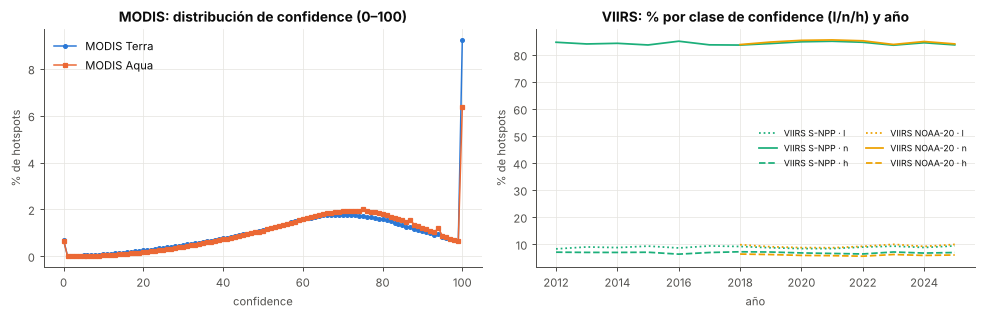

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
mo = I[I.instrument == 'modis'].copy(); mo['c'] = pd.to_numeric(mo.confidence, errors='coerce')
for s in ['Terra','Aqua']:
    q = mo[mo.satellite == s].groupby('c').n.sum(); ax[0].plot(q.index, 100 * q / q.sum(), color=SCOL[s], marker=SMK[s], ms=3, lw=1.2, label=SLAB[s])
ax[0].set(title='MODIS: distribución de confidence (0–100)', xlabel='confidence', ylabel='% de hotspots'); ax[0].legend()
vi = I[I.instrument != 'modis'].groupby(['satellite','year','confidence']).n.sum().unstack(fill_value=0)
vs = 100 * vi.div(vi.sum(axis=1), axis=0)
for s in ['N','N20']:
    for cl, ls in [('l',':'),('n','-'),('h','--')]:
        if cl in vs.columns: q = vs.loc[s][cl]; ax[1].plot(q.index, q.values, color=SCOL[s], ls=ls, lw=1.4, label=f'{SLAB[s]} · {cl}')
ax[1].set(title='VIIRS: % por clase de confidence (l/n/h) y año', xlabel='año', ylabel='% de hotspots'); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

### Hallazgos · inventario de valores
- **(a)** `type`: 0 vegetación presumida, 1 volcán activo, 2 otra fuente estática, 3 costa afuera ([tabla de atributos](https://www.earthdata.nasa.gov/data/tools/firms/active-fire-data-attributes-modis-viirs)). La tabla lo documenta solo para MODIS; en estos CSV también aparece en S-NPP y NOAA-20 con los mismos códigos 0–3 → **(c)** confirmar que el significado es el mismo en VIIRS.
- **(b)** 97.2–98.9 % de los hotspots son `type` 0. Fuentes estáticas (`type` 2): Terra 2.5 %, Aqua 1.1 %, S-NPP 2.5 %, NOAA-20 2.6 %. Volcán: 0.02–0.09 %. Costa afuera: 0.01 % (MODIS) y 0.17 % (VIIRS).
- **(b)** `version` **sin sufijo NRT** en todo el archivo (consistente con datos SP). MODIS: `6.2` (2000–2017), `6.03` (2018–2022), `61.03` (2023–2025); VIIRS: `2` en todos los años. **(c)** Ninguno de esos valores está en la tabla oficial (documenta 6.1, 6.1NRT, 1.0…): significado por verificar. Los cambios de 2018 y 2023 no producen un salto visible en la razón Aqua/S-NPP (§7), pero no se descarta una discontinuidad no medida.
- **(b)** Fracción nocturna: Terra 28 %, Aqua 6 %, S-NPP 24 %, NOAA-20 24 %. Terra de noche (≈22:30) detecta mucho más que Aqua (≈01:30).

## 3 · Cobertura temporal
**(b)** Los CSV solo contienen días con al menos una detección; un día ausente puede ser «sin datos» **o** «sin fuego».
Por eso se mira el total de los 6 países y se listan los huecos de 2 o más días consecutivos.

In [6]:
Dly = T['daily'].groupby(['satellite','date'], as_index=False)[['n','frp_sum']].sum()
Dly['date'] = pd.to_datetime(Dly.date)
rows = []; GAPM = {}
for s in [x for x in SATS if x in set(Dly.satellite)]:
    d = Dly[Dly.satellite == s].set_index('date').n
    full = pd.date_range(d.index.min(), d.index.max()); miss = full.difference(d.index)
    GAPM[s] = set((miss.year * 100 + miss.month).tolist())
    grp = (pd.Series(miss).diff().dt.days != 1).cumsum() if len(miss) else pd.Series([], dtype=int)
    gaps = pd.Series(miss).groupby(grp.values).agg(['min','max','size']) if len(miss) else pd.DataFrame(columns=['min','max','size'])
    rows.append({'satélite': SLAB[s], 'primer día': d.index.min().date(), 'último día': d.index.max().date(), 'días con datos': len(d),
                 'días ausentes': len(miss), 'huecos ≥2 días': int((gaps['size'] >= 2).sum()),
                 'hueco mayor (días)': int(gaps['size'].max()) if len(gaps) else 0})
    if len(gaps): globals().setdefault('GAPS', {})[s] = gaps[gaps['size'] >= 2].sort_values('size', ascending=False).head(8)
display(pd.DataFrame(rows))
for s, g in globals().get('GAPS', {}).items(): print(SLAB[s], '· huecos mayores:'); display(g)

,satélite,primer día,último día,días con datos,días ausentes,huecos ≥2 días,hueco mayor (días)
0,MODIS Terra,2000-11-01,2025-12-31,9135,57,6,17
1,MODIS Aqua,2002-07-04,2025-12-31,8556,26,2,16
2,VIIRS S-NPP,2012-01-20,2025-12-31,5060,35,5,15
3,VIIRS NOAA-20,2018-04-01,2025-12-31,2826,6,1,4


MODIS Terra · huecos mayores:


,min,max,size
1,2001-06-16,2001-07-02,17
7,2022-10-11,2022-10-22,12
2,2002-03-20,2002-03-28,9
6,2016-02-19,2016-02-27,9
4,2003-12-17,2003-12-23,7
5,2008-12-21,2008-12-22,2


MODIS Aqua · huecos mayores:


,min,max,size
3,2022-04-01,2022-04-16,16
1,2002-07-30,2002-08-07,9


VIIRS S-NPP · huecos mayores:


,min,max,size
2,2022-07-27,2022-08-10,15
4,2024-07-10,2024-07-15,6
3,2024-05-30,2024-06-03,5
5,2024-07-25,2024-07-28,4
7,2024-11-03,2024-11-05,3


VIIRS NOAA-20 · huecos mayores:


,min,max,size
1,2023-07-19,2023-07-22,4


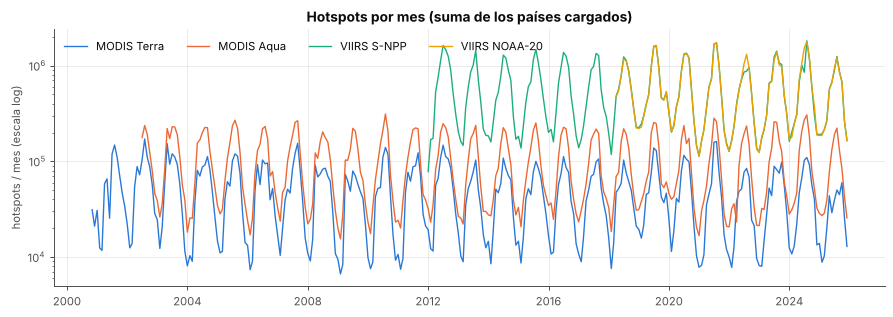

Primer día de Aqua en estos datos: 2002-07-04


In [7]:
fig, ax = plt.subplots(figsize=(10, 3.6))
mm = M.groupby(['satellite','date']).n_all.sum().unstack(0)
for s in [x for x in SATS if x in mm.columns]: ax.plot(mm.index, mm[s], color=SCOL[s], lw=1.1, label=SLAB[s])
ax.set_yscale('log'); ax.set(title='Hotspots por mes (suma de los países cargados)', ylabel='hotspots / mes (escala log)'); ax.legend(ncol=4)
plt.tight_layout(); plt.show()
print('Primer día de Aqua en estos datos:', P[P.satellite == 'Aqua'].date_min.min() if (P.satellite == 'Aqua').any() else 'sin datos')

### Hallazgos · cobertura temporal
- **(b)** Huecos de ≥ 2 días consecutivos sin ninguna detección en los 6 países: Terra 6 (mayores: 2001-06-16→07-02, 17 días; 2022-10-11→22, 12 días), Aqua 2 (2022-04-01→16, 16 días; 2002-07-30→08-07), S-NPP 5 (2022-07-27→08-10, 15 días; cuatro en 2024 de 3 a 6 días), NOAA-20 1 (2023-07-19→22, 4 días). Con seis países juntos, un día sin ninguna detección apunta a falta de datos, no a falta de fuego.
- **(c)** La causa de cada hueco (modo seguro, mantenimiento, procesamiento) no está verificada. En §7 se mide que **sesgan las razones** entre sensores.
- **(b)** El archivo termina en 2025-12-31: la anomalía de S-NPP de 2026 (Copernicus) queda fuera.

## 4 · Horas de paso (UTC y hora solar local) y su deriva
**(a)** Terra: 10:30 descendente; Aqua: 13:30 ascendente
([LAADS](https://ladsweb.modaps.eosdis.nasa.gov/missions-and-measurements/modis/)). S-NPP ~13:30 ascendente / ~01:30 descendente
([Schroeder et al. 2014](https://directreadout.sci.gsfc.nasa.gov/publications_documents/Schroeder_et_al_2014b_RSE.pdf)).
NOAA-20: misma órbita que S-NPP con ~50 min de separación (fuente secundaria, aquí se **mide**).
Terra y Aqua se desvían de su órbita nominal ([NASA](https://earthdata.nasa.gov/news/feature-articles/viirs-instruments-become-more-essential-terra-aqua-drift-traditional-orbits)); cuándo y cuánto: se mide abajo.
Hora solar local = UTC + lon/15 h (no huso político).

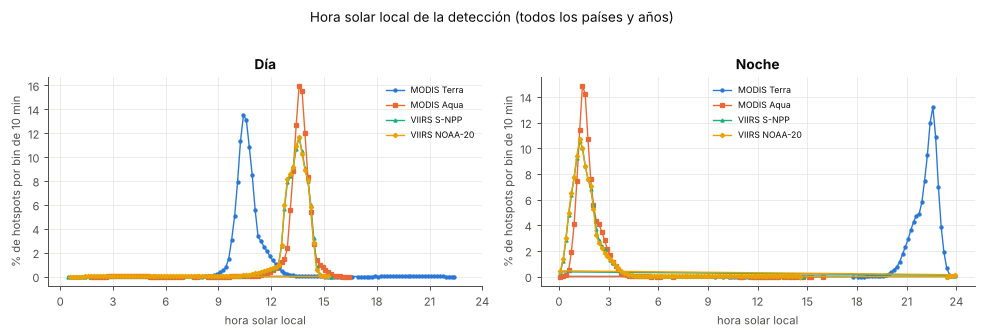

Hora solar local (h, reloj) de la detección


,satélite,día/noche,p10,mediana,p90,n
0,MODIS Terra,D,9.917,10.583,11.583,11042107
1,MODIS Terra,N,21.083,22.250,22.917,4380202
2,MODIS Aqua,D,13.083,13.583,14.250,27091552
3,MODIS Aqua,N,1.083,1.583,2.583,1815286
4,VIIRS S-NPP,D,12.750,13.417,14.250,76704617
5,VIIRS S-NPP,N,0.750,1.417,2.583,24028765
6,VIIRS NOAA-20,D,12.750,13.417,14.083,43241456
7,VIIRS NOAA-20,N,0.583,1.417,2.583,13868348


In [8]:
def hq(df, qs=(.1,.5,.9)):
    g = df[df.bin >= 0].groupby('bin').n.sum().sort_index(); c = (g.cumsum() / g.sum()).values
    return [g.index[min(np.searchsorted(c, q), len(g) - 1)] + 5 for q in qs]
L = H[H['var'] == 'lst']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for j, dn in enumerate(['D','N']):
    for s in [x for x in SATS if x in set(L.satellite)]:
        q = L[(L.satellite == s) & (L.daynight == dn) & (L.bin >= 0)].groupby('bin').n.sum()
        if q.sum() == 0: continue
        ax[j].plot(clock(q.index + 5), 100 * q / q.sum(), color=SCOL[s], marker=SMK[s], ms=2.5, lw=1.1, label=SLAB[s])
    ax[j].set(title='Día' if dn == 'D' else 'Noche', xlabel='hora solar local', ylabel='% de hotspots por bin de 10 min'); ax[j].legend(fontsize=7)
    ax[j].set_xticks(range(0, 25, 3))
plt.suptitle('Hora solar local de la detección (todos los países y años)', y=1.02); plt.tight_layout(); plt.show()
rows = []
for s in [x for x in SATS if x in set(L.satellite)]:
    for dn in ['D','N']:
        q = L[(L.satellite == s) & (L.daynight == dn)]
        if q.n.sum(): p10, p50, p90 = hq(q); rows.append({'satélite': SLAB[s], 'día/noche': dn, 'p10': clock(p10), 'mediana': clock(p50), 'p90': clock(p90), 'n': q.n.sum()})
tab_hora = pd.DataFrame(rows); print('Hora solar local (h, reloj) de la detección'); display(tab_hora)

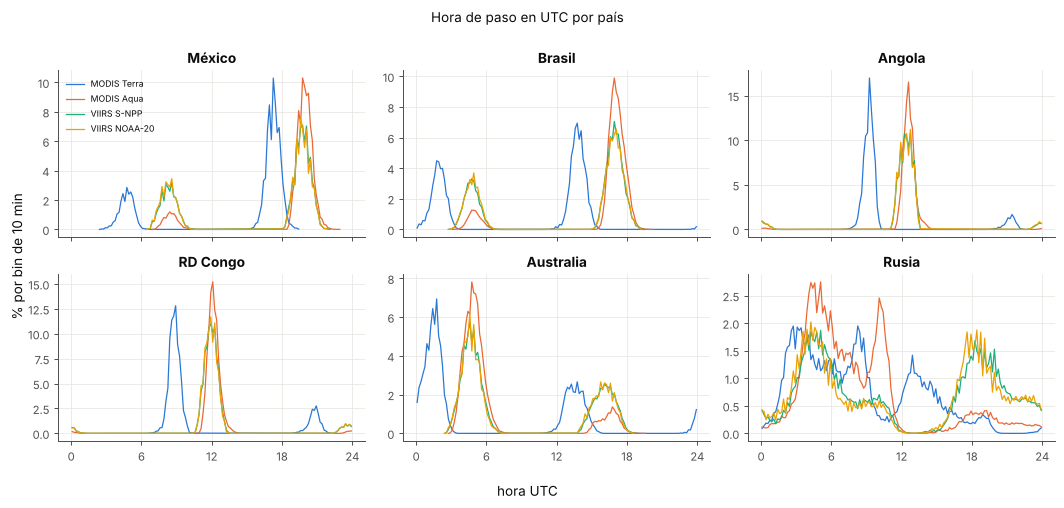

In [9]:
U = H[H['var'] == 'utc']
fig, axs = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True)
for ax, c in zip(axs.ravel(), COUNTRIES):
    for s in [x for x in SATS if x in set(U.satellite)]:
        q = U[(U.country == c) & (U.satellite == s) & (U.bin >= 0)].groupby('bin').n.sum()
        if q.sum(): ax.plot(q.index / 60 + 5 / 60, 100 * q / q.sum(), color=SCOL[s], lw=1, label=SLAB[s])
    ax.set(title=CSH[c]); ax.set_xticks(range(0, 25, 6))
axs[0, 0].legend(fontsize=7); fig.supxlabel('hora UTC'); fig.supylabel('% por bin de 10 min'); plt.suptitle('Hora de paso en UTC por país', y=1.0); plt.tight_layout(); plt.show()

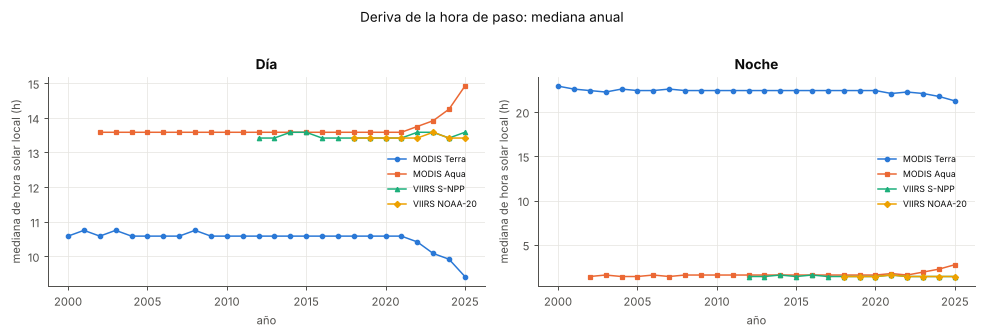

satellite   Aqua            N          N20        Terra       
daynight       D     N      D     N      D     N      D      N
year                                                          
2000         NaN   NaN    NaN   NaN    NaN   NaN 10.580 22.920
2001         NaN   NaN    NaN   NaN    NaN   NaN 10.750 22.580
2002      13.580 1.420    NaN   NaN    NaN   NaN 10.580 22.420
2003      13.580 1.580    NaN   NaN    NaN   NaN 10.750 22.250
2004      13.580 1.420    NaN   NaN    NaN   NaN 10.580 22.580
2005      13.580 1.420    NaN   NaN    NaN   NaN 10.580 22.420
2006      13.580 1.580    NaN   NaN    NaN   NaN 10.580 22.420
2007      13.580 1.420    NaN   NaN    NaN   NaN 10.580 22.580
2008      13.580 1.580    NaN   NaN    NaN   NaN 10.750 22.420
2009      13.580 1.580    NaN   NaN    NaN   NaN 10.580 22.420
2010      13.580 1.580    NaN   NaN    NaN   NaN 10.580 22.420
2011      13.580 1.580    NaN   NaN    NaN   NaN 10.580 22.420
2012      13.580 1.580 13.420 1.420    NaN   NaN 10.580 22.420
2013      13.580 1.580 13.420 1.420    NaN   NaN 10.580 22.420
2014      13.580 1.580 13.580 1.580    NaN   NaN 10.580 22.420
2015      13.580 1.580 13.580 1.420    NaN   NaN 10.580 22.420
2016      13.580 1.580 13.420 1.580    NaN   NaN 10.580 22.420
2017      13.580 1.580 13.420 1.420    NaN   NaN 10.580 22.420
2018      13.580 1.580 13.420 1.420 13.420 1.420 10.580 22.420
2019      13.580 1.580 13.420 1.420 13.420 1.420 10.580 22.420
2020      13.580 1.580 13.420 1.420 13.420 1.420 10.580 22.420
2021      13.580 1.750 13.420 1.580 13.420 1.580 10.580 22.080
2022      13.750 1.580 13.580 1.420 13.420 1.420 10.420 22.250
2023      13.920 1.920 13.580 1.420 13.580 1.420 10.080 22.080
2024      14.250 2.250 13.420 1.420 13.420 1.420  9.920 21.750
2025      14.920 2.750 13.580 1.420 13.420 1.420  9.420 21.250

Cambio total de la mediana (min):


primer año  hora inicial  último año  hora final  cambio (min)
satellite daynight                                                                
Aqua      D          2,002.000        13.583   2,025.000      14.917        80.000
          N          2,002.000         1.417   2,025.000       2.750        80.000
N         D          2,012.000        13.417   2,025.000      13.583        10.000
          N          2,012.000         1.417   2,025.000       1.417         0.000
N20       D          2,018.000        13.417   2,025.000      13.417         0.000
          N          2,018.000         1.417   2,025.000       1.417         0.000
Terra     D          2,000.000        10.583   2,025.000       9.417       -70.000
          N          2,000.000        22.917   2,025.000      21.250      -100.000

In [10]:
# (i) Deriva: mediana anual de hora solar local por satélite (día y noche), todos los países juntos
rows = []
for (s, dn, y), q in L.groupby(['satellite','daynight','year']):
    if q.n.sum() > 200: rows.append({'satellite': s, 'daynight': dn, 'year': y, 'hora': clock(hq(q, (.5,))[0])})
drift = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for j, dn in enumerate(['D','N']):
    for s in [x for x in SATS if x in set(drift.satellite)]:
        q = drift[(drift.satellite == s) & (drift.daynight == dn)]
        if len(q): ax[j].plot(q.year, q.hora, color=SCOL[s], marker=SMK[s], ms=3.5, lw=1.2, label=SLAB[s])
    ax[j].set(title='Día' if dn == 'D' else 'Noche', xlabel='año', ylabel='mediana de hora solar local (h)'); ax[j].legend(fontsize=7)
plt.suptitle('Deriva de la hora de paso: mediana anual', y=1.02); plt.tight_layout(); plt.show()
dd = drift.pivot_table(index='year', columns=['satellite','daynight'], values='hora'); display(dd.round(2))
dtab = drift.groupby(['satellite','daynight']).apply(lambda q: pd.Series({'primer año': q.year.min(), 'hora inicial': q.sort_values('year').hora.iloc[0],
        'último año': q.year.max(), 'hora final': q.sort_values('year').hora.iloc[-1], 'cambio (min)': 60 * (q.sort_values('year').hora.iloc[-1] - q.sort_values('year').hora.iloc[0])}))
print('Cambio total de la mediana (min):'); display(dtab)

### Hallazgos · hora de paso y deriva
- **(b)** Mediana de hora solar local: Terra 10.58 h (día) / 22.25 h (noche); Aqua 13.58 / 1.58; S-NPP 13.42 / 1.42; NOAA-20 13.42 / 1.42. Concuerda con las horas nominales **(a)** (Terra 10:30, Aqua 13:30; S-NPP ~13:30 y ~01:30).
- **(b)** **NOAA-20 tiene la misma hora solar local que S-NPP** (Δt mediano por celda ≈ 0.4 min, §8). La separación de ~50 min de la fuente secundaria no aparece en hora solar local; **(b)** inferido: corresponde a la fase orbital (UTC), no a la hora local en una celda.
- **(b)** Deriva: las medianas de Terra y Aqua son estables hasta 2021 y cambian después. Aqua de día: 13.58 h (hasta 2021) → 13.75 (2022) → 13.92 (2023) → 14.25 (2024) → **14.92 (2025)**, es decir +80 min frente a 2002; de noche 1.42 → 2.75 h. Terra de día: 10.58 → 10.42 → 10.08 → 9.92 → **9.42** (−70 min); de noche ≈ 22.4 → 21.25 h. VIIRS no se desvía (0–10 min). **(a)** La deriva de Terra y Aqua está documentada ([NASA](https://earthdata.nasa.gov/news/feature-articles/viirs-instruments-become-more-essential-terra-aqua-drift-traditional-orbits)); aquí se mide su inicio (2021–2022) y magnitud.

## 5 · FRP, saturación, píxel (`scan`/`track`)
**(a)** El píxel de MODIS crece hacia el borde del barrido (área ×~9.6; [Hawbaker/MDPI](https://www.mdpi.com/2072-4292/12/10/1561/htm)); en VIIRS 375 m el píxel
crece fuera del nadir ([FIRMS](https://earthdata.nasa.gov/data/instruments/viirs/viirs-i-band-375-m-active-fire-data)). `scan` y `track` dan el tamaño real del píxel
([tabla de atributos](https://www.earthdata.nasa.gov/data/tools/firms/active-fire-data-attributes-modis-viirs)). El canal I4 se satura y el FRP solo es fiable en fuegos pequeños
([FIRMS VIIRS I-band](https://webarchive.library.unt.edu/web/20201218013512/https://earthdata.nasa.gov/earth-observation-data/near-real-time/firms/viirs-i-band-active-fire-data)).

FRP (cuantiles aproximados al borde inferior de un bin log de 8/década)


n  % FRP nulo  % FRP = 0  FRP p50 (MW)     p90     p99
satélite      dn                                                               
MODIS Aqua    D   27091552       0.000      0.012        23.714 100.000 421.697
              N    1815286       0.000      0.217        13.335  56.234 237.137
VIIRS S-NPP   D   76704617       0.000      0.016         5.623  23.714 100.000
              N   24028765       0.000      0.002         1.334   4.217  23.714
VIIRS NOAA-20 D   43241456       0.000      0.023         5.623  23.714 100.000
              N   13868348       0.000      0.002         1.334   5.623  23.714
MODIS Terra   D   11042107       0.000      0.010        17.783  74.989 421.697
              N    4380202       0.000      0.151        13.335  56.234 237.137

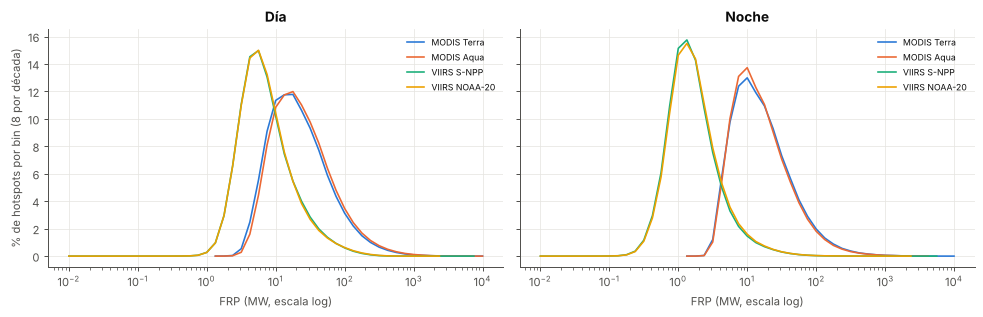

In [11]:
Hf = H[H['var'] == 'frp']
def hist_q(q, qs=(.5,.9,.99)):
    pos = q[q.bin > 0].groupby('bin').n.sum().sort_index(); tot = q.n.sum(); c = (q[q.bin <= 0].n.sum() + pos.cumsum()).values / tot
    return [pos.index[min(np.searchsorted(c, x), len(pos) - 1)] for x in qs]
rows = []
for (s, dn), q in Hf.groupby(['satellite','daynight']):
    tot = q.n.sum(); p = hist_q(q)
    rows.append({'satélite': SLAB[s], 'dn': dn, 'n': tot, '% FRP nulo': 100 * q[q.bin == -1].n.sum() / tot, '% FRP = 0': 100 * q[q.bin == 0].n.sum() / tot,
                 'FRP p50 (MW)': p[0], 'p90': p[1], 'p99': p[2]})
tab_frp = pd.DataFrame(rows).set_index(['satélite','dn']); print('FRP (cuantiles aproximados al borde inferior de un bin log de 8/década)'); display(tab_frp)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for j, dn in enumerate(['D','N']):
    for s in [x for x in SATS if x in set(Hf.satellite)]:
        q = Hf[(Hf.satellite == s) & (Hf.daynight == dn) & (Hf.bin > 0)].groupby('bin').n.sum()
        tot = Hf[(Hf.satellite == s) & (Hf.daynight == dn)].n.sum()
        if tot: ax[j].plot(q.index, 100 * q / tot, color=SCOL[s], lw=1.3, label=SLAB[s])
    ax[j].set_xscale('log'); ax[j].set(title='Día' if dn == 'D' else 'Noche', xlabel='FRP (MW, escala log)'); ax[j].legend(fontsize=7)
ax[0].set_ylabel('% de hotspots por bin (8 por década)'); plt.tight_layout(); plt.show()

,variable,satélite,máximo (K),% en el bin máximo,% en los 2 K superiores
0,bright_ti4/brightness,MODIS Terra,500.000,0.026,0.026
1,bright_ti4/brightness,MODIS Aqua,510.000,0.000,0.000
2,bright_ti4/brightness,VIIRS S-NPP,367.000,7.470,7.470
3,bright_ti4/brightness,VIIRS NOAA-20,367.000,6.627,6.627
4,bright_ti5/bright_t31,MODIS Terra,400.000,0.000,0.000
5,bright_ti5/bright_t31,MODIS Aqua,400.000,0.036,0.036
6,bright_ti5/bright_t31,VIIRS S-NPP,423.000,0.000,0.000
7,bright_ti5/bright_t31,VIIRS NOAA-20,381.000,0.000,0.000


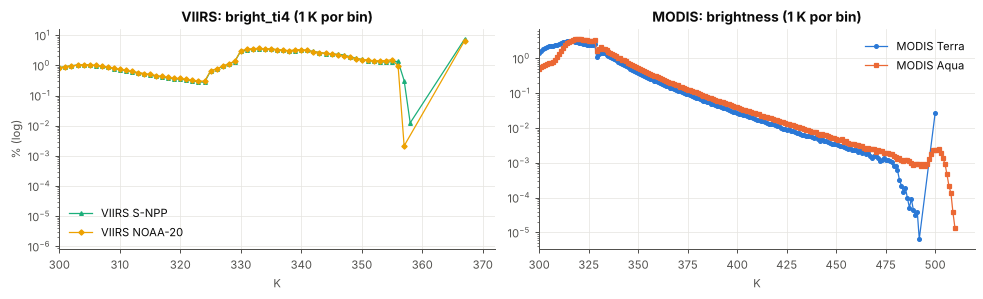

In [12]:
# Saturación: ¿bright_ti4 / brightness / bright_t31 / bright_ti5 se apilan en un tope?
rows = []
for v in ['tb4','tb5']:
    for s in [x for x in SATS if x in set(H.satellite)]:
        q = H[(H['var'] == v) & (H.satellite == s) & (H.bin > 0)].groupby('bin').n.sum()
        if q.sum() == 0: continue
        top = q.index.max(); rows.append({'variable': ('bright_ti4/brightness' if v == 'tb4' else 'bright_ti5/bright_t31'), 'satélite': SLAB[s], 'máximo (K)': top,
            '% en el bin máximo': 100 * q.loc[top] / q.sum(), '% en los 2 K superiores': 100 * q[q.index >= top - 1].sum() / q.sum()})
display(pd.DataFrame(rows))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for s in ['N','N20']:
    q = H[(H['var'] == 'tb4') & (H.satellite == s) & (H.bin > 0)].groupby('bin').n.sum()
    if len(q): ax[0].semilogy(q.index, q.values / q.sum() * 100, color=SCOL[s], marker=SMK[s], ms=3, lw=1, label=SLAB[s])
ax[0].set(title='VIIRS: bright_ti4 (1 K por bin)', xlabel='K', ylabel='% (log)'); ax[0].set_xlim(300, 372); ax[0].legend()
for s in ['Terra','Aqua']:
    q = H[(H['var'] == 'tb4') & (H.satellite == s) & (H.bin > 0)].groupby('bin').n.sum()
    if len(q): ax[1].semilogy(q.index, q.values / q.sum() * 100, color=SCOL[s], marker=SMK[s], ms=3, lw=1, label=SLAB[s])
ax[1].set(title='MODIS: brightness (1 K por bin)', xlabel='K'); ax[1].set_xlim(300, 520); ax[1].legend()
plt.tight_layout(); plt.show()

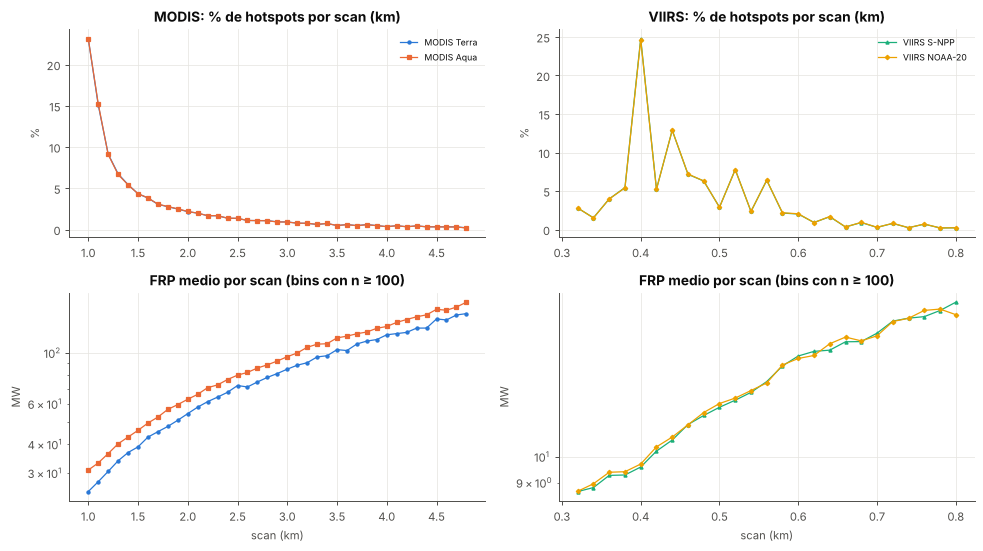

Área de píxel = scan × track (km²)


,satélite,área mín (km²),p50,p90,p99,máx,máx/p50,% con área > 2× la mediana
0,MODIS Terra,1.000,1.430,4.640,9.000,9.600,6.713,21.760
1,MODIS Aqua,1.000,1.430,4.640,9.000,9.600,6.713,21.644
2,VIIRS S-NPP,0.137,0.199,0.343,0.578,0.624,3.128,6.812
3,VIIRS NOAA-20,0.137,0.201,0.348,0.578,0.624,3.106,6.856


In [13]:
PX = T['pixel']
def pxsum(s):
    q = PX[PX.satellite == s]; return q.groupby('scan', as_index=False).agg(n=('n','sum'), frp=('frp_sum','sum'))
fig, ax = plt.subplots(2, 2, figsize=(11, 6.2))
for j, grp in enumerate([['Terra','Aqua'], ['N','N20']]):
    for s in grp:
        if s not in set(PX.satellite): continue
        q = pxsum(s); w = 0.1 if j == 0 else 0.02
        q['b'] = (q.scan / w).round() * w; g = q.groupby('b').agg(n=('n','sum'), frp=('frp','sum')).reset_index()
        ax[0, j].plot(g.b, 100 * g.n / g.n.sum(), color=SCOL[s], marker=SMK[s], ms=2.5, lw=1, label=SLAB[s])
        gg = g[g.n >= 100]; ax[1, j].plot(gg.b, gg.frp / gg.n, color=SCOL[s], marker=SMK[s], ms=2.5, lw=1, label=SLAB[s])
    ax[0, j].set(title=('MODIS' if j == 0 else 'VIIRS') + ': % de hotspots por scan (km)', ylabel='%'); ax[0, j].legend(fontsize=7)
    ax[1, j].set(title='FRP medio por scan (bins con n ≥ 100)', xlabel='scan (km)', ylabel='MW'); ax[1, j].set_yscale('log')
plt.tight_layout(); plt.show()
rows = []
for s in [x for x in SATS if x in set(PX.satellite)]:
    q = PX[PX.satellite == s].assign(area=lambda d: d.scan * d.track).sort_values('area'); c = q.n.cumsum() / q.n.sum()
    nad = q.area.iloc[0] if q.area.iloc[0] > 0 else np.nan
    pc_ = [q.area.values[min(np.searchsorted(c.values, x), len(q) - 1)] for x in (.5,.9,.99)]
    rows.append({'satélite': SLAB[s], 'área mín (km²)': q.area.min(), 'p50': pc_[0], 'p90': pc_[1], 'p99': pc_[2], 'máx': q.area.max(),
                 'máx/p50': q.area.max() / pc_[0], '% con área > 2× la mediana': 100 * q[q.area > 2 * pc_[0]].n.sum() / q.n.sum()})
print('Área de píxel = scan × track (km²)'); display(pd.DataFrame(rows))

In [14]:
# Duplicados: exactos (a) y cercanos (misma fecha/hora UTC y posición redondeada) + re-detección en otra pasada el mismo día
dup = P.groupby('satellite').agg(filas=('rows','sum'), exactos=('n_exact_dup','sum'), cerca_0001=('n_dup_0001deg_same_time','sum'),
        cerca_001=('n_dup_001deg_same_time','sum'), pos=('n_pos001_day','sum'), pos_multi=('n_pos001_day_multipass','sum'))
dup = dup.loc[[s for s in SATS if s in dup.index]]
out = pd.DataFrame({'% exactos': 100 * dup.exactos / dup.filas, '% mismo tiempo y pos a 0.001° (~110 m)': 100 * dup.cerca_0001 / dup.filas,
                    '% mismo tiempo y pos a 0.01° (~1 km)': 100 * dup.cerca_001 / dup.filas,
                    '% de posiciones 0.01°-día con ≥2 pasadas': 100 * dup.pos_multi / dup.pos})
out.index = [SLAB[s] for s in out.index]; display(out)

,% exactos,% mismo tiempo y pos a 0.001° (~110 m),% mismo tiempo y pos a 0.01° (~1 km),% de posiciones 0.01°-día con ≥2 pasadas
MODIS Terra,0.000,0.000,3.739,2.479
MODIS Aqua,0.000,0.001,3.928,0.746
VIIRS S-NPP,0.000,0.451,36.096,9.321
VIIRS NOAA-20,0.000,0.410,34.962,9.277


### Hallazgos · FRP, saturación, píxel y duplicados
- **(b)** FRP nulo: 0 %. FRP = 0: ≤ 0.22 % (máximo en Aqua de noche, 0.217 %); VIIRS ≤ 0.023 %.
- **(b)** FRP mediano de día: Aqua 23.7 MW, Terra 17.8, S-NPP 5.6, NOAA-20 5.6; p99: MODIS ≈ 422 MW, VIIRS ≈ 100 MW. De noche: MODIS ≈ 13.3 MW, VIIRS ≈ 1.3 MW (cuantiles aproximados por bins log de 8/década).
- **(b)** **Saturación en VIIRS**: 7.5 % de los hotspots de S-NPP y 6.6 % de NOAA-20 están exactamente en 367 K de `bright_ti4` (el tope). **(a)** La saturación del canal I4 y que el FRP solo sea fiable en fuegos pequeños están documentadas ([FIRMS](https://webarchive.library.unt.edu/web/20201218013512/https://earthdata.nasa.gov/earth-observation-data/near-real-time/firms/viirs-i-band-active-fire-data)); el valor 367 K es observado. MODIS: `brightness` máximo 500–510 K con < 0.03 % en el tope y `bright_t31` máximo 400 K con ≤ 0.04 %: sin apilamiento relevante.
- **(b)** Píxel (scan × track): MODIS 1.0–9.6 km² (mediana 1.43; 21.7 % con área > 2× la mediana), VIIRS 0.137–0.624 km² (mediana 0.20; 6.8 % > 2×). El factor ×9.6 de MODIS en el borde coincide con lo documentado **(a)** ([MDPI](https://www.mdpi.com/2072-4292/12/10/1561/htm)); en VIIRS la razón máx/mediana es 3.1.
- **(b)** Duplicados: exactos 0. Mismo instante y posición a 0.001° (~110 m): MODIS ≈ 0 %, VIIRS 0.41–0.45 %. A 0.01° (~1 km) la métrica mide **agrupamiento**, no duplicación: 35–36 % de los hotspots VIIRS comparten instante y celda de 0.01° con otro (varios píxeles de 375 m dentro de ~1 km²) frente a 3.7–3.9 % en MODIS. Es una de las causas geométricas de que VIIRS cuente muchos más hotspots. Además, 9.3 % (VIIRS) y 0.7–2.5 % (MODIS) de las posiciones-día tienen detecciones en ≥ 2 pasadas.

## 6 · Fuentes persistentes, `type` y falsos positivos
**(b)** Celdas de 0.01° con detecciones en ≥ 30 días distintos de un año (tope de 2000 por archivo): candidatas a llamas de gas, industria, minas o volcanes.
El `type` (documentado) separa vegetación (0), volcán (1), fuente estática (2) y costa afuera (3).
**(a)** La tabla oficial dice que las detecciones nocturnas de baja confianza en VIIRS solo ocurren en una región del Atlántico Sur y que FIRMS las quita de NRT
([atributos](https://www.earthdata.nasa.gov/data/tools/firms/active-fire-data-attributes-modis-viirs); ATBD de VIIRS: [Anomalía Magnética del Atlántico Sur](https://www.star.nesdis.noaa.gov/aerosoltraining/documents/VIIRS_AF_Iband_ATBD_v1.0_20200506.pdf)).
**(c)** ¿Conserva el archivo SP esas detecciones? Se mide `n_night_lo` (VIIRS `l` de noche) por celda.

In [15]:
PS = T['persistent']
tb = PS.groupby(['country','satellite']).agg(celdas=('n','size'), hotspots=('n','sum'), dias_max=('n_days','max'), tipo2=('type_mode', lambda s: 100 * (s == 2).mean()),
        noche=('n_night', 'sum')).reset_index(); tb['% noche'] = 100 * tb.noche / tb.hotspots
tb = tb.drop(columns='noche'); tb['country'] = tb.country.map(CSH); display(tb.rename(columns={'tipo2': '% celdas con type=2'}))
tot = P.groupby(['country','satellite']).rows.sum().rename('total').reset_index()
sh = PS.groupby(['country','satellite']).n.sum().rename('persist').reset_index().merge(tot)
sh['% de hotspots en celdas persistentes'] = 100 * sh.persist / sh.total; sh['country'] = sh.country.map(CSH)
print('Peso de las celdas persistentes sobre el total de cada país y satélite'); display(sh[['country','satellite','% de hotspots en celdas persistentes']])
top = PS[PS.satellite.isin(['N','N20'])].sort_values('n_days', ascending=False).groupby('country').head(5)[['country','satellite','lat','lon','n_days','n','frp_mean','type_mode']]
top['country'] = top.country.map(CSH); print('Top 5 celdas persistentes por país (VIIRS)'); display(top)

,country,satellite,celdas,hotspots,dias_max,% celdas con type=2,% noche
0,Angola,N,88,8934,171,70.455,73.573
1,Angola,N20,42,4080,171,78.571,75.711
2,Angola,Terra,2,73,35,50.000,72.603
3,Australia,Aqua,111,5275,87,94.595,46.370
4,Australia,N,1046,197340,301,86.998,82.770
5,Australia,N20,643,108176,295,91.135,84.655
6,Australia,Terra,186,10574,130,97.312,49.943
7,Brasil,Aqua,120,7055,102,100.000,58.852
8,Brasil,N,1668,231007,294,77.038,77.401
9,Brasil,N20,1003,131504,276,74.377,75.320


Peso de las celdas persistentes sobre el total de cada país y satélite


,country,satellite,% de hotspots en celdas persistentes
0,Angola,N,0.050
1,Angola,N20,0.039
2,Angola,Terra,0.005
3,Australia,Aqua,0.151
4,Australia,N,1.155
5,Australia,N20,1.145
6,Australia,Terra,0.358
7,Brasil,Aqua,0.114
8,Brasil,N,1.201
9,Brasil,N20,1.214


Top 5 celdas persistentes por país (VIIRS)


,country,satellite,lat,lon,n_days,n,frp_mean,type_mode
19766,México,N,16.202,-95.171,321,1098,6.156,2
29874,México,N,20.579,-101.171,316,1175,3.811,2
26053,México,N,20.579,-101.171,314,1239,6.129,2
20946,México,N,16.202,-95.171,313,1067,6.345,2
14436,México,N20,16.203,-95.169,313,872,7.391,2
30622,Rusia,N,61.349,112.809,313,1250,29.301,2
28013,Rusia,N,61.349,112.809,310,1249,28.817,2
19262,Rusia,N,60.148,109.100,308,1188,19.612,2
9635,Rusia,N20,61.349,112.809,307,1275,29.873,2
21670,Rusia,N,60.148,109.100,306,1249,20.934,2


VIIRS (S-NPP + NOAA-20): detecciones nocturnas y nocturnas con confidence l


,n,noche,noche_baja,% noche,% de nocturnos con confidence l
country,,,,,
Angola,28264864,1823121,0,6.450,0.000
Australia,26526855,9728014,0,36.672,0.000
Brasil,30059725,9489698,0,31.569,0.000
RD Congo,40279677,2877662,0,7.144,0.000
México,6620656,2095555,0,31.652,0.000
Rusia,26091409,11883063,0,45.544,0.000


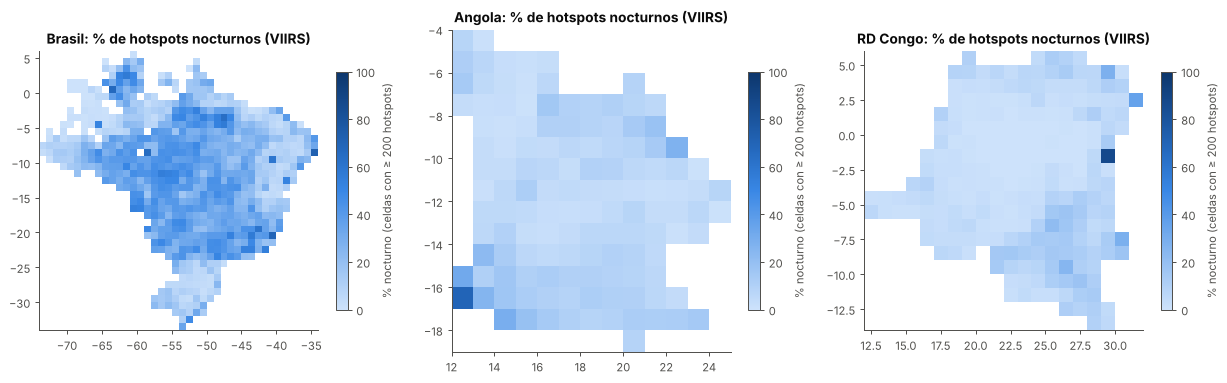

In [16]:
def asp(ext): return 'auto' if (ext[1] - ext[0]) > 90 else 'equal'
def grid(df, val):
    la0, la1, lo0, lo1 = df.cell_lat.min(), df.cell_lat.max(), df.cell_lon.min(), df.cell_lon.max()
    Z = np.full((la1 - la0 + 1, lo1 - lo0 + 1), np.nan); Z[(df.cell_lat - la0).values, (df.cell_lon - lo0).values] = df[val].values
    return Z, (lo0, lo1 + 1, la0, la1 + 1)
V = CM[CM.satellite.isin(['N','N20'])].groupby(['country','cell_lat','cell_lon'], as_index=False)[['n','n_night','n_night_lo','n_hi']].sum()
tab_saa = V.groupby('country').agg(n=('n','sum'), noche=('n_night','sum'), noche_baja=('n_night_lo','sum')); tab_saa['% noche'] = 100 * tab_saa.noche / tab_saa.n
tab_saa['% de nocturnos con confidence l'] = 100 * tab_saa.noche_baja / tab_saa.noche; tab_saa.index = tab_saa.index.map(CSH)
print('VIIRS (S-NPP + NOAA-20): detecciones nocturnas y nocturnas con confidence l'); display(tab_saa)
cs = [c for c in ['Brazil','Angola','Democratic_Republic_of_the_Congo'] if c in COUNTRIES]
if cs:
    fig, axs = plt.subplots(1, len(cs), figsize=(4.6 * len(cs), 4.2), squeeze=False)
    for ax, c in zip(axs[0], cs):
        q = V[(V.country == c) & (V.n >= 200)].copy(); q['f'] = 100 * q.n_night / q.n; Z, ext = grid(q, 'f')
        im = ax.imshow(Z, origin='lower', extent=ext, cmap=BLUES, aspect=asp(ext), vmin=0, vmax=100); ax.set_title(CSH[c] + ': % de hotspots nocturnos (VIIRS)'); ax.grid(False)
        fig.colorbar(im, ax=ax, shrink=.7, label='% nocturno (celdas con ≥ 200 hotspots)')
    plt.tight_layout(); plt.show()

### Hallazgos · fuentes persistentes y confidence nocturno
- **(b)** Las celdas persistentes (≥ 30 días/año en 0.01°) concentran 11.5–12.0 % de los hotspots VIIRS de **Rusia** y 11.7–12.0 % de **México**, frente a ≤ 1.2 % en Brasil y Australia y ≤ 0.35 % en RD Congo y Angola; en MODIS pesan 1.4–5.1 %. Entre 74 y 100 % de esas celdas son `type` 2 en México, Rusia, Australia y Brasil. Ejemplos: 61.35°N 112.81°E y 60.15°N 109.10°E (Rusia; 300+ días/año; FRP medio 20–30 MW), 20.58°N 101.17°W (México), 20.24°S 40.24°W (Brasil), 34.46°S 150.88°E (Australia). **(c)** Su origen (llamas de gas, refinería, siderurgia, minería) es inferido y no se verificó.
- **(a/b)** En RD Congo las persistentes son `type` 1 (volcán activo, documentado): 1.41°S 29.20°E, FRP medio 60–75 MW; que sea el Nyiragongo es una identificación **(b)** por ubicación.
- **(b)** **Cero** detecciones nocturnas con `confidence` = `l` en los 6 países, incluidos Brasil y Angola. **(a)** La tabla oficial dice que el `l` nocturno ocurre solo en una región del Atlántico Sur y que FIRMS lo quita de NRT; **(c)** en el archivo SP parece ocurrir lo mismo. Los mapas de fracción nocturna no muestran un patrón difuso en el sur de Brasil ni en Angola: las celdas con > 80 % nocturno son puntuales (Nyiragongo, una celda de la costa suroeste de Angola). Un posible efecto de la Anomalía Magnética del Atlántico Sur en `n`/`h` **no se puede evaluar** con estas tablas.

## 7 · Solapes y razones entre sensores (cuantificar, sin corregir)
Razón = hotspots (o FRP) del primer sensor / el segundo, sumada por año **solo en los meses en que ambos tienen datos**.
La transferencia hacia atrás (antes de 2012) supone que la relación es estable: por eso se reporta año por año.
Sensibilidad al filtro de `confidence`: MODIS ≥30/50/80 contra VIIRS n+h y solo h.

Guardado: Data/analisis/02_eda/resultados/razones_anuales.csv 1056 filas


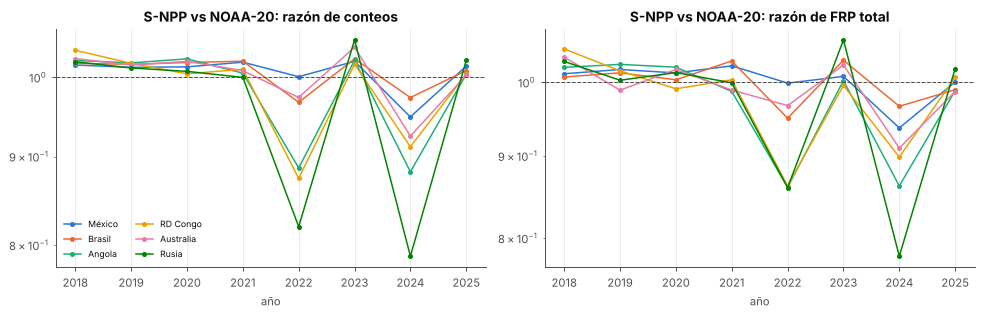

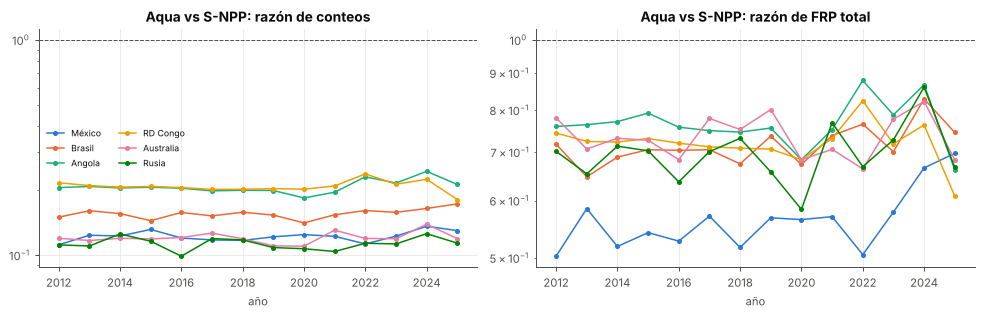

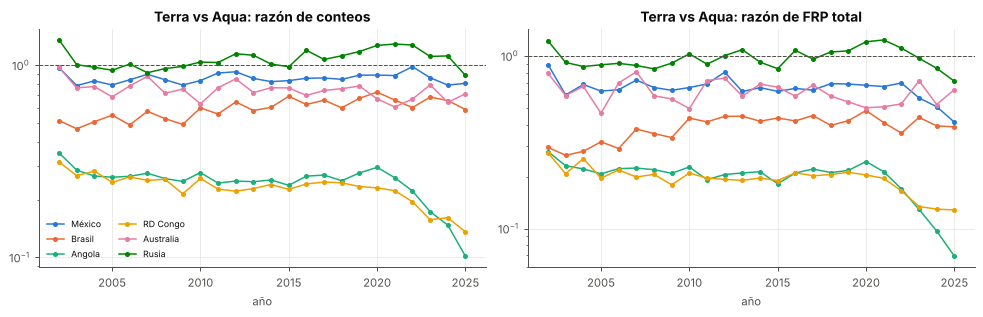

In [17]:
COLS = [c for c in M.columns if c.startswith(('n_','frp_'))]
Mm = M.groupby(['country','satellite','ym'])[COLS].sum().reset_index(); Mm['year'] = Mm.ym // 100
PAIRS = [('S-NPP vs NOAA-20','N','N20'), ('Aqua vs S-NPP','Aqua','N'), ('Terra vs Aqua','Terra','Aqua')]
FILT = {'S-NPP vs NOAA-20': [('todo','n_all','n_all'),('VIIRS n+h','n_nh','n_nh'),('VIIRS h','n_h','n_h')],
        'Aqua vs S-NPP': [('todo','n_all','n_all'),('MODIS≥30 vs VIIRS n+h','n_ge30','n_nh'),('MODIS≥50 vs VIIRS n+h','n_ge50','n_nh'),('MODIS≥80 vs VIIRS h','n_ge80','n_h')],
        'Terra vs Aqua': [('todo','n_all','n_all'),('≥30','n_ge30','n_ge30'),('≥50','n_ge50','n_ge50'),('≥80','n_ge80','n_ge80')]}
def ratios(A, B, ca='n_all', cb='n_all', drop=()):
    fa, fb = ca.replace('n_', 'frp_'), cb.replace('n_', 'frp_')
    a = Mm[Mm.satellite == A].set_index(['country','ym']); b = Mm[Mm.satellite == B].set_index(['country','ym'])
    j = pd.DataFrame({'year': a.year, 'pres_a': a.n_all, 'nA': a[ca], 'fA': a[fa]}).join(
        pd.DataFrame({'pres_b': b.n_all, 'nB': b[cb], 'fB': b[fb]}), how='inner')
    j = j[(j.pres_a > 0) & (j.pres_b > 0)]          # solo meses en que ambos sensores tienen detecciones
    if drop: j = j[~j.index.get_level_values('ym').isin(drop)]
    g = j.groupby(['country','year']).agg(nA=('nA','sum'), nB=('nB','sum'), fA=('fA','sum'), fB=('fB','sum'), meses=('nA','size')).reset_index()
    g['ratio_n'] = g.nA / g.nB.replace(0, np.nan); g['ratio_frp'] = g.fA / g.fB.replace(0, np.nan)
    return g
RZ = []
for name, A, B in PAIRS:
    if not ((Mm.satellite == A).any() and (Mm.satellite == B).any()): continue
    for lab, ca, cb in FILT[name]:
        g = ratios(A, B, ca, cb); g.insert(0, 'filtro', lab); g.insert(0, 'par', name); RZ.append(g)
RZ = pd.concat(RZ, ignore_index=True); RZ.to_csv(OUT / 'razones_anuales.csv', index=False)
print('Guardado:', OUT / 'razones_anuales.csv', len(RZ), 'filas')
for name, A, B in PAIRS:
    q = RZ[(RZ.par == name) & (RZ.filtro == 'todo')]
    if q.empty: continue
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for c in COUNTRIES:
        qq = q[q.country == c]
        if len(qq):
            ax[0].plot(qq.year, qq.ratio_n, color=CCOL[c], marker='o', ms=3, lw=1.2, label=CSH[c]); ax[1].plot(qq.year, qq.ratio_frp, color=CCOL[c], marker='o', ms=3, lw=1.2, label=CSH[c])
    for a_, t_ in zip(ax, ['razón de conteos', 'razón de FRP total']):
        a_.axhline(1, color='#52514e', lw=.8, ls='--'); a_.set(title=f'{name}: {t_}', xlabel='año'); a_.set_yscale('log')
    ax[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

In [18]:
# Escala de la diferencia, resumida: mediana (entre años) de la razón por país y filtro
sc = RZ.groupby(['par','filtro','country']).agg(años=('year','nunique'), mediana_razon_n=('ratio_n','median'), min_n=('ratio_n','min'), max_n=('ratio_n','max'),
                                                mediana_razon_frp=('ratio_frp','median')).reset_index(); sc['country'] = sc.country.map(CSH)
display(sc[sc.filtro == 'todo'])
print('Sensibilidad al filtro de confidence (mediana de la razón de conteos):')
display(sc.pivot_table(index=['par','country'], columns='filtro', values='mediana_razon_n'))

,par,filtro,country,años,mediana_razon_n,min_n,max_n,mediana_razon_frp
18,Aqua vs S-NPP,todo,Angola,14,0.206,0.184,0.245,0.759
19,Aqua vs S-NPP,todo,Australia,14,0.119,0.110,0.139,0.729
20,Aqua vs S-NPP,todo,Brasil,14,0.157,0.141,0.173,0.705
21,Aqua vs S-NPP,todo,RD Congo,14,0.208,0.181,0.238,0.721
22,Aqua vs S-NPP,todo,México,14,0.122,0.112,0.136,0.566
23,Aqua vs S-NPP,todo,Rusia,14,0.113,0.099,0.126,0.701
36,S-NPP vs NOAA-20,todo,Angola,8,1.012,0.882,1.025,0.995
37,S-NPP vs NOAA-20,todo,Australia,8,1.013,0.925,1.041,0.989
38,S-NPP vs NOAA-20,todo,Brasil,8,1.018,0.967,1.025,1.006
39,S-NPP vs NOAA-20,todo,RD Congo,8,1.008,0.874,1.037,1.000


Sensibilidad al filtro de confidence (mediana de la razón de conteos):


filtro                      MODIS≥30 vs VIIRS n+h  MODIS≥50 vs VIIRS n+h  MODIS≥80 vs VIIRS h  VIIRS h  VIIRS n+h  todo   ≥30   ≥50   ≥80
par              country                                                                                                                 
Aqua vs S-NPP    Angola                     0.232                  0.199                0.670      NaN        NaN 0.206   NaN   NaN   NaN
                 Australia                  0.126                  0.108                0.552      NaN        NaN 0.119   NaN   NaN   NaN
                 Brasil                     0.164                  0.140                0.825      NaN        NaN 0.157   NaN   NaN   NaN
                 México                     0.133                  0.116                0.648      NaN        NaN 0.122   NaN   NaN   NaN
                 RD Congo                   0.216                  0.181                0.873      NaN        NaN 0.208   NaN   NaN   NaN
                 Rusia                      0.108                  0.089                0.815      NaN        NaN 0.113   NaN   NaN   NaN
S-NPP vs NOAA-20 Angola                       NaN                    NaN                  NaN    1.122      1.019 1.012   NaN   NaN   NaN
                 Australia                    NaN                    NaN                  NaN    1.158      1.017 1.013   NaN   NaN   NaN
                 Brasil                       NaN                    NaN                  NaN    1.190      1.026 1.018   NaN   NaN   NaN
                 México                       NaN                    NaN                  NaN    1.138      1.021 1.015   NaN   NaN   NaN
                 RD Congo                     NaN                    NaN                  NaN    1.147      1.013 1.008   NaN   NaN   NaN
                 Rusia                        NaN                    NaN                  NaN    1.221      1.011 1.010   NaN   NaN   NaN
Terra vs Aqua    Angola                       NaN                    NaN                  NaN      NaN        NaN 0.258 0.258 0.257 0.225
                 Australia                    NaN                    NaN                  NaN      NaN        NaN 0.753 0.744 0.737 0.737
                 Brasil                       NaN                    NaN                  NaN      NaN        NaN 0.599 0.590 0.572 0.517
                 México                       NaN                    NaN                  NaN      NaN        NaN 0.848 0.840 0.824 0.736
                 RD Congo                     NaN                    NaN                  NaN      NaN        NaN 0.237 0.237 0.238 0.225
                 Rusia                        NaN                    NaN                  NaN      NaN        NaN 1.054 1.042 1.038 1.111

In [19]:
# Sensibilidad: excluir los meses con huecos de datos (de la sección 3) de cualquiera de los dos sensores del par
rows = []
for name, A, B in PAIRS:
    if A not in GAPM or B not in GAPM: continue
    drop = GAPM[A] | GAPM[B]
    g0 = ratios(A, B); g1 = ratios(A, B, drop=drop)
    r0 = g0.groupby('year').apply(lambda d: d.nA.sum() / d.nB.sum()); r1 = g1.groupby('year').apply(lambda d: d.nA.sum() / d.nB.sum())
    rows.append(pd.DataFrame({'par': name, 'con huecos': r0, 'sin meses con huecos': r1, 'meses excluidos': len(drop)}).reset_index())
GR = pd.concat(rows); GR.to_csv(OUT / 'razones_sin_huecos.csv', index=False)
for name in GR.par.unique():
    q = GR[GR.par == name].set_index('year')[['con huecos','sin meses con huecos']]
    print(name, '· CV entre años: con huecos %.3f · sin huecos %.3f' % (q.iloc[:, 0].std() / q.iloc[:, 0].mean(), q.iloc[:, 1].std() / q.iloc[:, 1].mean()))
    display(q.T.round(3))

S-NPP vs NOAA-20 · CV entre años: con huecos 0.052 · sin huecos 0.006


year,2018,2019,2020,2021,2022,2023,2024,2025
con huecos,1.026,1.017,1.014,1.009,0.909,1.030,0.906,1.007
sin meses con huecos,1.026,1.017,1.014,1.009,1.012,1.018,1.016,1.007


Aqua vs S-NPP · CV entre años: con huecos 0.058 · sin huecos 0.032


year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
con huecos,0.152,0.168,0.163,0.164,0.163,0.163,0.161,0.154,0.153,0.159,0.182,0.166,0.186,0.165
sin meses con huecos,0.151,0.168,0.163,0.164,0.163,0.163,0.161,0.154,0.153,0.159,0.164,0.166,0.158,0.165


Terra vs Aqua · CV entre años: con huecos 0.120 · sin huecos 0.132


year,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
con huecos,0.652,0.548,0.486,0.475,0.517,0.514,0.506,0.462,0.490,0.503,0.595,0.451,0.504,0.478,0.481,0.500,0.495,0.544,0.544,0.534,0.431,0.459,0.419,0.349
sin meses con huecos,0.691,0.555,0.486,0.475,0.517,0.514,0.510,0.462,0.490,0.503,0.595,0.451,0.504,0.478,0.487,0.500,0.495,0.544,0.544,0.534,0.407,0.459,0.419,0.349


Años: 14 · Spearman(razón de conteos, hora de paso de Aqua de día) = 0.68 · Spearman(razón, año) = 0.37


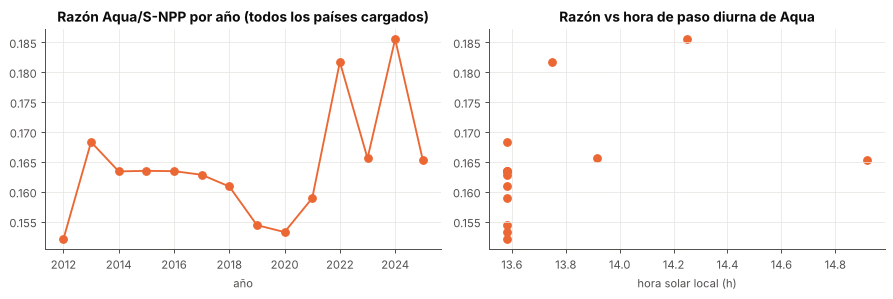

In [20]:
# (i) ¿La razón Aqua/S-NPP tiene tendencia ligada a la deriva de Aqua?
q = RZ[(RZ.par == 'Aqua vs S-NPP') & (RZ.filtro == 'todo')].groupby('year').apply(lambda d: pd.Series({'ratio_n': d.nA.sum() / d.nB.sum(), 'ratio_frp': d.fA.sum() / d.fB.sum()}))
dr = drift[(drift.satellite == 'Aqua') & (drift.daynight == 'D')].set_index('year').hora
j = q.join(dr.rename('hora_Aqua_dia'), how='inner')
if len(j) >= 4:
    r1 = j.ratio_n.rank().corr(j.hora_Aqua_dia.rank()); r2 = j.ratio_n.rank().corr(pd.Series(j.index, index=j.index).rank())
    print(f'Años: {len(j)} · Spearman(razón de conteos, hora de paso de Aqua de día) = {r1:.2f} · Spearman(razón, año) = {r2:.2f}')
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); ax[0].plot(j.index, j.ratio_n, 'o-', color=SCOL['Aqua']); ax[0].set(title='Razón Aqua/S-NPP por año (todos los países cargados)', xlabel='año')
    ax[1].scatter(j.hora_Aqua_dia, j.ratio_n, color=SCOL['Aqua']); ax[1].set(title='Razón vs hora de paso diurna de Aqua', xlabel='hora solar local (h)'); plt.tight_layout(); plt.show()
else: print('Muy pocos años solapados para evaluar tendencia')

,mediana_umbral,min,max,razon_mediana
country,,,,
Angola,15.941,13.200,16.911,4.864
Australia,20.473,16.798,23.706,8.371
Brasil,17.190,14.508,21.260,6.372
RD Congo,13.082,11.401,13.862,4.813
México,15.669,14.169,16.472,8.168
Rusia,16.833,15.062,20.862,8.836


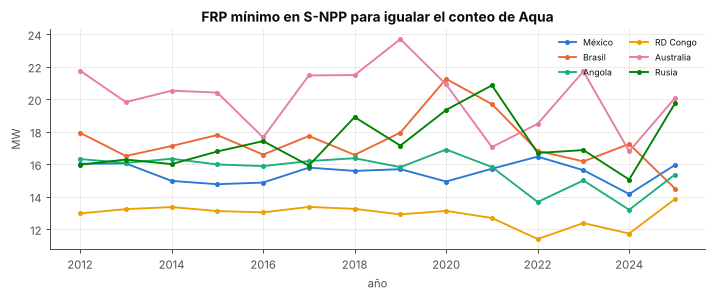

In [21]:
# (m) Umbral de FRP en S-NPP que iguala los conteos de Aqua (solo cuantificar)
def frp_thr(country, year, sat_v='N', sat_m='Aqua'):
    h = Hf[(Hf.country == country) & (Hf.year == year)]
    target = h[h.satellite == sat_m].n.sum(); v = h[(h.satellite == sat_v) & (h.bin > 0)].groupby('bin').n.sum().sort_index(ascending=False)
    tot = h[h.satellite == sat_v].n.sum()
    if target == 0 or tot == 0: return np.nan, np.nan
    if target >= v.sum(): return 0.0, tot / target
    c = v.cumsum().values; i = np.searchsorted(c, target); above = c[i - 1] if i > 0 else 0; f = (target - above) / v.iloc[i]
    return v.index[i] * 10 ** (1 / 8) / 10 ** (f / 8), tot / target
rows = []
for c in COUNTRIES:
    for y in sorted(Hf[(Hf.country == c) & (Hf.satellite == 'N')].year.unique()):
        if ((Hf.country == c) & (Hf.year == y) & (Hf.satellite == 'Aqua')).any():
            t_, r_ = frp_thr(c, y); rows.append({'country': c, 'year': y, 'umbral_FRP_MW': t_, 'razon_VIIRS_sobre_Aqua': r_})
UM = pd.DataFrame(rows); UM.to_csv(OUT / 'umbral_frp_equivalente.csv', index=False)
if len(UM):
    display(UM.groupby('country').agg(mediana_umbral=('umbral_FRP_MW','median'), min=('umbral_FRP_MW','min'), max=('umbral_FRP_MW','max'), razon_mediana=('razon_VIIRS_sobre_Aqua','median')).rename(index=CSH))
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for c in COUNTRIES:
        q = UM[UM.country == c]; ax.plot(q.year, q.umbral_FRP_MW, color=CCOL[c], marker='o', ms=3, label=CSH[c])
    ax.set(title='FRP mínimo en S-NPP para igualar el conteo de Aqua', xlabel='año', ylabel='MW'); ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

### Hallazgos · razones entre sensores
- **(b)** **S-NPP vs NOAA-20** (abr-2018 a 2025): razón mediana de conteos 1.008–1.018 por país y de FRP 0.99–1.01. Con `confidence` n+h la razón es 1.01–1.03, pero **solo `h`** da 1.12–1.22: S-NPP asigna más hotspots a `h` que NOAA-20, así que la clase `h` no es equivalente entre sensores aunque n+h sí lo sea.
- **(b)** Los años con razón baja (2022: 0.909; 2024: 0.906) coinciden con los huecos de S-NPP. Excluyendo los meses con huecos, la razón queda en 1.007–1.026 todos los años (CV entre años 0.052 → 0.006). Para Aqua/S-NPP el CV baja de 0.058 a 0.032 (2022 y 2024: 0.182 y 0.186 → 0.164 y 0.158). **Los huecos deben excluirse al calibrar.**
- **(b)** **Aqua vs S-NPP** (2012–2025): S-NPP cuenta 5–9× más hotspots. Razón de conteos mediana por país: 0.113 Rusia, 0.119 Australia, 0.122 México, 0.157 Brasil, 0.206 Angola, 0.208 RD Congo. La razón de **FRP total** es 0.57–0.76: varía menos entre países (≈ ±15 %) que la de conteos (≈ ±30 %), aunque es más ruidosa de un año a otro (en la figura, entre ≈ 0.5 y 0.9).
- **(b)** La razón Aqua/S-NPP es **estable en el tiempo** (sin huecos: 0.151–0.168 entre 2012 y 2025; CV anual por país 5–7 %), sin salto en 2018 ni 2023 (cambios de `version` de MODIS) y sin efecto visible de la deriva de Aqua. La correlación de 0.68 con la hora de paso de Aqua se debe sobre todo a los años con huecos. **(c)** Que la misma relación valga antes de 2012 (para transferir hacia atrás) no se puede comprobar: no hay VIIRS antes de 2012.
- **(b)** El filtro de `confidence` cambia mucho la razón Aqua/S-NPP: sin filtro 0.11–0.21; MODIS ≥ 30 vs VIIRS n+h 0.11–0.23; ≥ 50 vs n+h 0.09–0.20; ≥ 80 vs h 0.55–0.87.
- **(b)** FRP mínimo en S-NPP que iguala los conteos de Aqua: 13–20 MW (medianas por país: 13.1 RD Congo, 15.7 México, 15.9 Angola, 16.8 Rusia, 17.2 Brasil, 20.5 Australia; S-NPP cuenta 4.8–8.8× más). Es una medida de escala, no una corrección.
- **(b)** Dejar solo `type` 0 casi no cambia Aqua/S-NPP (< 1 % en Angola, Australia, Brasil y RD Congo; +3.4 % México; +7.1 % Rusia) y la dispersión entre países apenas baja (1.84× → 1.73×): las fuentes estáticas **no explican** la diferencia entre países.
- **(b)** **Terra vs Aqua**: razón de conteos mediana 0.24 RD Congo, 0.26 Angola, 0.60 Brasil, 0.75 Australia, 0.85 México, 1.05 Rusia. El efecto de la hora de paso (10:30 vs 13:30) es enorme y depende de la región. Desde 2022 la razón cae (≈ 0.53 en 2021 → 0.35 en 2025), coherente con la deriva de ambos satélites.

In [22]:
# Efecto de excluir type != 0 (fuentes estáticas, volcanes, costa afuera) en la razón de conteos Aqua/S-NPP (años 2012-2025, año completo)
I = T['inventory']
def annual(sat, only0):
    q = I[(I.satellite == sat) & ((I.type == 0) if only0 else True)]
    return q.groupby(['country','year']).n.sum()
rows = []
for only0 in (False, True):
    a, b = annual('Aqua', only0), annual('N', only0); r = (a / b).dropna().loc[lambda x: x.index.get_level_values('year') >= 2012]
    rows.append(r.groupby('country').median().rename('solo type 0' if only0 else 'todos los type'))
tt = pd.concat(rows, axis=1); tt['cambio %'] = 100 * (tt['solo type 0'] / tt['todos los type'] - 1); tt.index = tt.index.map(CSH)
print('Mediana anual de Aqua/S-NPP (conteos):'); display(tt)
print('Dispersión entre países (máx/mín): todos %.2f · solo type 0 %.2f' % (tt['todos los type'].max() / tt['todos los type'].min(), tt['solo type 0'].max() / tt['solo type 0'].min()))

Mediana anual de Aqua/S-NPP (conteos):


,todos los type,solo type 0,cambio %
country,,,
Angola,0.206,0.206,0.049
Australia,0.119,0.120,0.657
Brasil,0.157,0.158,0.453
RD Congo,0.208,0.208,0.277
México,0.122,0.127,3.424
Rusia,0.113,0.121,7.125


Dispersión entre países (máx/mín): todos 1.84 · solo type 0 1.73


## 8 · Zonas equicomparables (resultado central)
Para cada par, año y día/noche: celda de 1° con ≥ 5 hotspots de **cada** sensor y mediana de hora solar local de ambos a ≤ tolerancia → **comparable** (opción B, hora de paso empírica).
Cobertura = % de los hotspots de cada sensor (en los años de solape) que caen en celdas comparables.
**Limitación (b):** una celda sin al menos 5 detecciones de ambos sensores no puede evaluarse (no hay píxeles sin fuego); esos hotspots cuentan como *no cubiertos*.

In [23]:
NMIN = 5; TOLS = (30, 60, 90)
cpb = CP[['country','year','satellite','daynight','cell_lat','cell_lon','n','lst_med']]
KEY = ['country','year','daynight','cell_lat','cell_lon']
def pair_table(A, B):
    a = cpb[cpb.satellite == A]; b = cpb[cpb.satellite == B]
    yrs = a[['country','year']].drop_duplicates().merge(b[['country','year']].drop_duplicates())
    m = a.merge(yrs).drop(columns='satellite').merge(b.merge(yrs).drop(columns='satellite'), on=KEY, how='outer', suffixes=('_a','_b'))
    m['dt'] = m.lst_med_a - m.lst_med_b; m['valida'] = (m.n_a >= NMIN) & (m.n_b >= NMIN); return m
PT = {name: pair_table(A, B) for name, A, B in PAIRS if (cpb.satellite == A).any() and (cpb.satellite == B).any()}
rows = []
for name, m in PT.items():
    for tol in TOLS:
        ok = m.valida & (m.dt.abs() <= tol)
        for (c, dn), g in m.assign(ok=ok).groupby(['country','daynight']):
            rows.append({'par': name, 'tol_min': tol, 'country': c, 'daynight': dn, 'cobertura_A_%': 100 * g[g.ok].n_a.sum() / max(g.n_a.sum(), 1),
                         'cobertura_B_%': 100 * g[g.ok].n_b.sum() / max(g.n_b.sum(), 1), 'celdas_comparables': int(g.ok.sum()), 'celdas_validas': int(g.valida.sum())})
COB = pd.DataFrame(rows); COB.to_csv(OUT / 'cobertura_equicomparable.csv', index=False)
resu = COB[COB.tol_min == 60].pivot_table(index=['par','country'], columns='daynight', values=['cobertura_A_%','cobertura_B_%']).round(1)
print('Cobertura a ±60 min (% de hotspots de cada sensor en celdas comparables; A = primer sensor del par)'); display(resu)
print('Sensibilidad a la tolerancia (día, cobertura de A, %):')
display(COB[COB.daynight == 'D'].pivot_table(index=['par','country'], columns='tol_min', values='cobertura_A_%').round(1))

Cobertura a ±60 min (% de hotspots de cada sensor en celdas comparables; A = primer sensor del par)


cobertura_A_%         cobertura_B_%        
daynight                                                      D       N             D       N
par              country                                                                     
Aqua vs S-NPP    Angola                                  92.800  91.600        92.900  81.000
                 Australia                               92.500  90.300        92.200  86.300
                 Brazil                                  94.700  94.100        95.400  91.500
                 Democratic_Republic_of_the_Congo        93.400  91.400        92.500  86.200
                 Mexico                                  93.400  89.300        93.900  82.700
                 Russian_Federation                      95.600  89.000        95.800  76.700
S-NPP vs NOAA-20 Angola                                 100.000 100.000       100.000 100.000
                 Australia                               99.800  99.800        99.900  99.900
                 Brazil                                 100.000 100.000       100.000 100.000
                 Democratic_Republic_of_the_Congo       100.000  99.700       100.000  99.900
                 Mexico                                 100.000  99.900       100.000  99.900
                 Russian_Federation                      99.700  99.700        99.600  99.500
Terra vs Aqua    Angola                                   0.000   0.000         0.000   0.000
                 Australia                                0.000   0.000         0.000   0.000
                 Brazil                                   0.000   0.000         0.000   0.000
                 Democratic_Republic_of_the_Congo         0.000   0.000         0.000   0.000
                 Mexico                                   0.000   0.000         0.000   0.000
                 Russian_Federation                      22.600   0.000        19.500   0.000

Sensibilidad a la tolerancia (día, cobertura de A, %):


tol_min                                                30      60      90
par              country                                                 
Aqua vs S-NPP    Angola                            83.700  92.800 100.000
                 Australia                         83.300  92.500  99.400
                 Brazil                            84.500  94.700  99.900
                 Democratic_Republic_of_the_Congo  84.900  93.400 100.000
                 Mexico                            84.300  93.400  99.700
                 Russian_Federation                85.600  95.600  98.700
S-NPP vs NOAA-20 Angola                           100.000 100.000 100.000
                 Australia                         95.700  99.800  99.900
                 Brazil                            99.800 100.000 100.000
                 Democratic_Republic_of_the_Congo 100.000 100.000 100.000
                 Mexico                            99.500 100.000 100.000
                 Russian_Federation                94.900  99.700  99.800
Terra vs Aqua    Angola                             0.000   0.000   0.000
                 Australia                          0.000   0.000   0.000
                 Brazil                             0.000   0.000   0.000
                 Democratic_Republic_of_the_Congo   0.000   0.000   0.000
                 Mexico                             0.000   0.000   0.000
                 Russian_Federation                 7.900  22.600  51.400

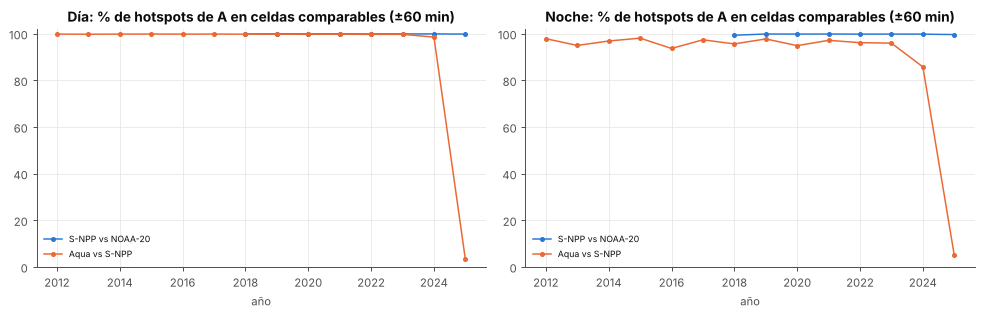

Aqua vs S-NPP, día: cobertura de A (%) y Δt mediano (min) por año


year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
cobertura_A_%,99.900,99.800,99.900,99.900,99.800,99.900,99.800,99.800,99.800,99.800,99.700,99.800,98.600,3.300
cobertura_B_%,99.800,99.700,99.800,99.800,99.800,99.800,99.700,99.700,99.700,99.800,99.600,99.700,98.300,3.600
dt_mediano_min,8.900,7.200,1.200,2.900,5.700,7.200,7.700,7.200,6.400,6.900,9.200,20.700,43.500,75.200


In [24]:
rows = []
for name, m in PT.items():
    for (y, dn), g in m.groupby(['year','daynight']):
        ok = g.valida & (g.dt.abs() <= 60)
        rows.append({'par': name, 'year': y, 'daynight': dn, 'cobertura_A_%': 100 * g[ok].n_a.sum() / max(g.n_a.sum(), 1),
                     'cobertura_B_%': 100 * g[ok].n_b.sum() / max(g.n_b.sum(), 1), 'dt_mediano_min': g[g.valida].dt.median()})
CY = pd.DataFrame(rows); CY.to_csv(OUT / 'cobertura_equicomparable_por_anio.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for j, dn in enumerate(['D','N']):
    for (name, _, _), col in zip(PAIRS[:2], ['#2a78d6', '#eb6834']):
        q = CY[(CY.par == name) & (CY.daynight == dn)]
        if len(q): ax[j].plot(q.year, q['cobertura_A_%'], marker='o', ms=3, lw=1.2, color=col, label=name)
    ax[j].set(title=('Día' if dn == 'D' else 'Noche') + ': % de hotspots de A en celdas comparables (±60 min)', xlabel='año', ylim=(0, 102)); ax[j].legend(fontsize=7)
plt.tight_layout(); plt.show()
print('Aqua vs S-NPP, día: cobertura de A (%) y Δt mediano (min) por año'); display(CY[(CY.par == 'Aqua vs S-NPP') & (CY.daynight == 'D')].set_index('year')[['cobertura_A_%','cobertura_B_%','dt_mediano_min']].round(1).T)

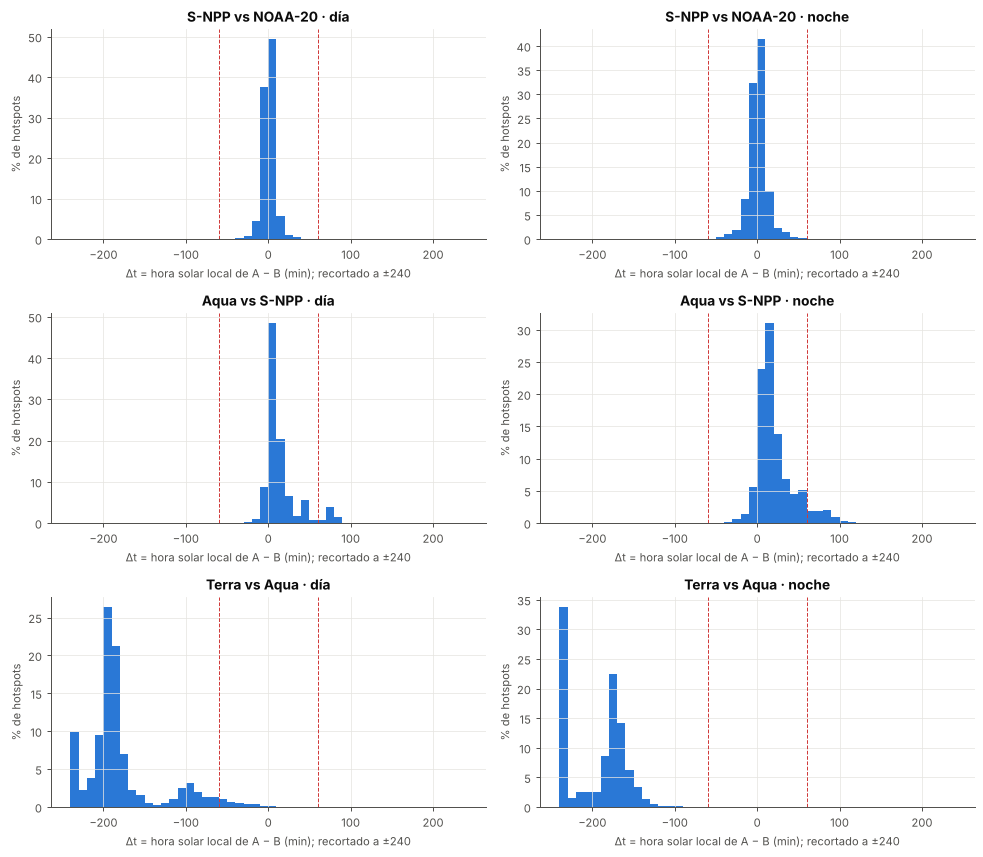

Δt mediano ponderado por hotspots (min) y % de hotspots dentro de ±60 min, entre las celdas válidas:


Δt mediano  % dentro de ±60
par              daynight                             
Aqua vs S-NPP    D              8.959           93.681
                 N             15.312           92.956
S-NPP vs NOAA-20 D              0.405           99.966
                 N              0.433           99.945
Terra vs Aqua    D           -180.866            3.401
                 N           -181.644            0.000

In [25]:
fig, axs = plt.subplots(len(PT), 2, figsize=(11, 3.2 * len(PT)), squeeze=False)
for i, (name, m) in enumerate(PT.items()):
    for j, dn in enumerate(['D','N']):
        q = m[m.valida & (m.daynight == dn)]
        if q.empty: continue
        w = q.n_a + q.n_b; axs[i, j].hist(q.dt.clip(-240, 240), bins=np.arange(-240, 241, 10), weights=w / w.sum() * 100, color='#2a78d6')
        for t in (-60, 60): axs[i, j].axvline(t, color='#d03b3b', lw=.8, ls='--')
        axs[i, j].set(title=f'{name} · {"día" if dn == "D" else "noche"}', xlabel='Δt = hora solar local de A − B (min); recortado a ±240', ylabel='% de hotspots')
plt.tight_layout(); plt.show()
q = pd.concat([m[m.valida].assign(par=n) for n, m in PT.items()])
print('Δt mediano ponderado por hotspots (min) y % de hotspots dentro de ±60 min, entre las celdas válidas:')
display(q.groupby(['par','daynight']).apply(lambda d: pd.Series({'Δt mediano': np.median(np.repeat(d.dt.values, np.minimum((d.n_a + d.n_b).astype(int).values, 50))),
    '% dentro de ±60': 100 * ((d.n_a + d.n_b)[d.dt.abs() <= 60]).sum() / (d.n_a + d.n_b).sum()})))

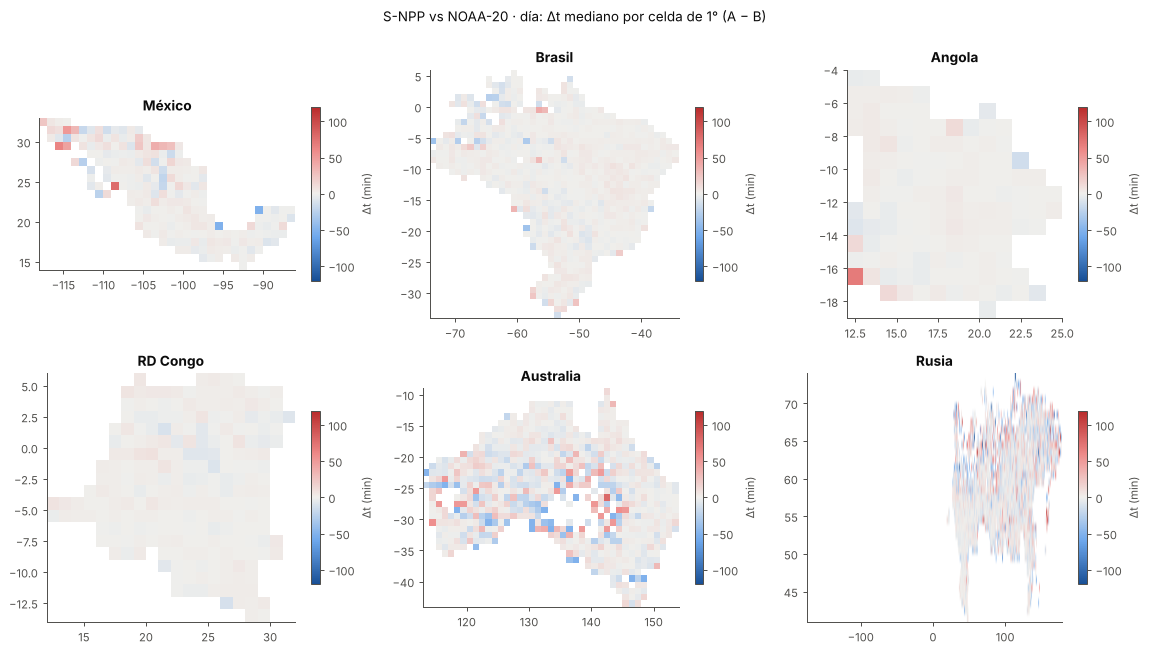

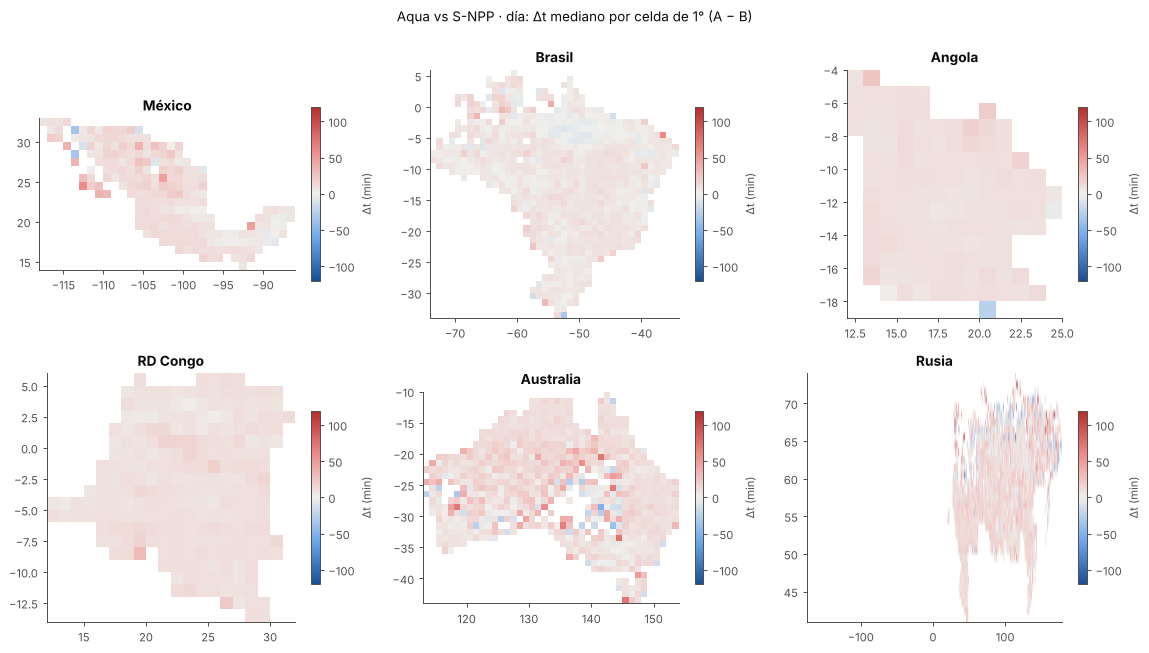

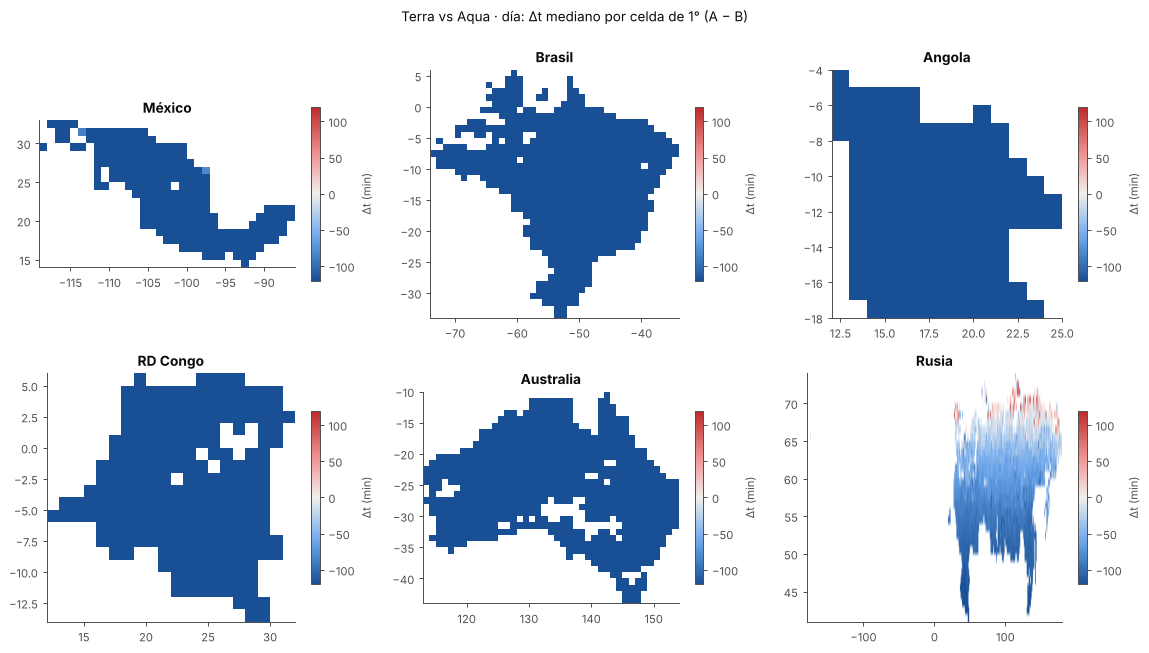

In [26]:
def dt_map(name, dn):
    m = PT[name]; q = m[m.valida & (m.daynight == dn)].groupby(['country','cell_lat','cell_lon'], as_index=False).agg(dt=('dt','median'), n=('n_a','sum'))
    cs = [c for c in COUNTRIES if c in set(q.country)]
    if not cs: return
    fig, axs = plt.subplots(2, 3, figsize=(13, 7.2)); axs = axs.ravel()
    for ax in axs: ax.axis('off')
    for ax, c in zip(axs, cs):
        ax.axis('on'); Z, ext = grid(q[q.country == c], 'dt'); im = ax.imshow(Z, origin='lower', extent=ext, cmap=DIV, norm=TwoSlopeNorm(0, -120, 120), aspect=asp(ext)); ax.grid(False)
        ax.set_title(CSH[c]); fig.colorbar(im, ax=ax, shrink=.7, label='Δt (min)')
    plt.suptitle(f'{name} · {"día" if dn == "D" else "noche"}: Δt mediano por celda de 1° (A − B)', y=1.0); plt.tight_layout(); plt.show()
for name in PT:
    dt_map(name, 'D')

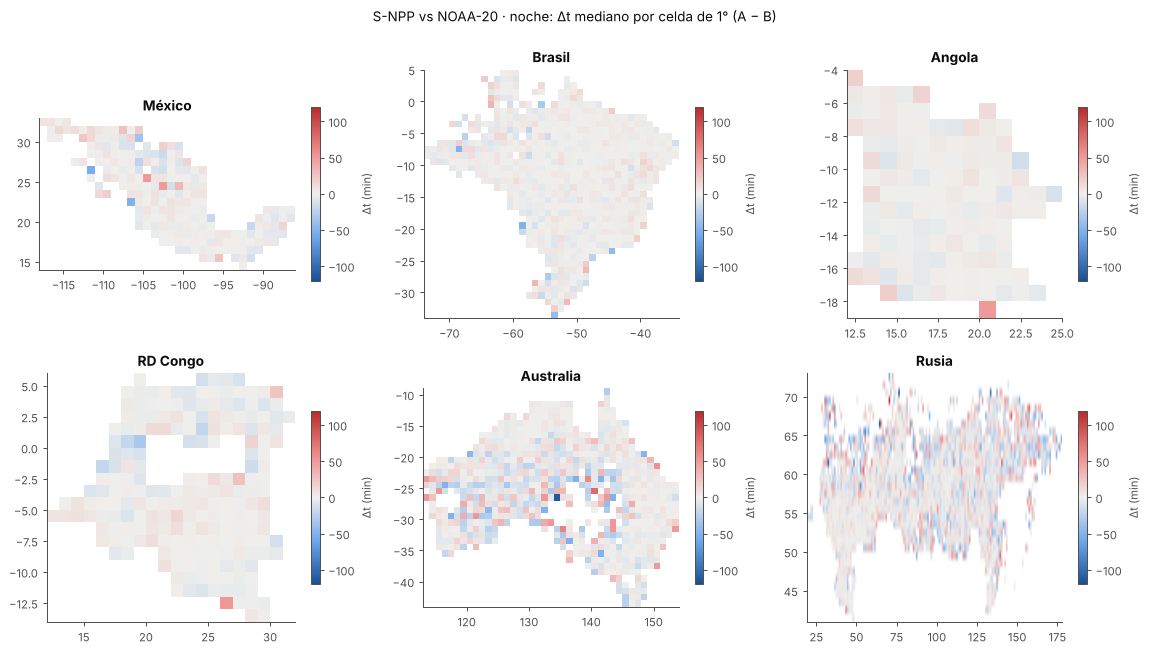

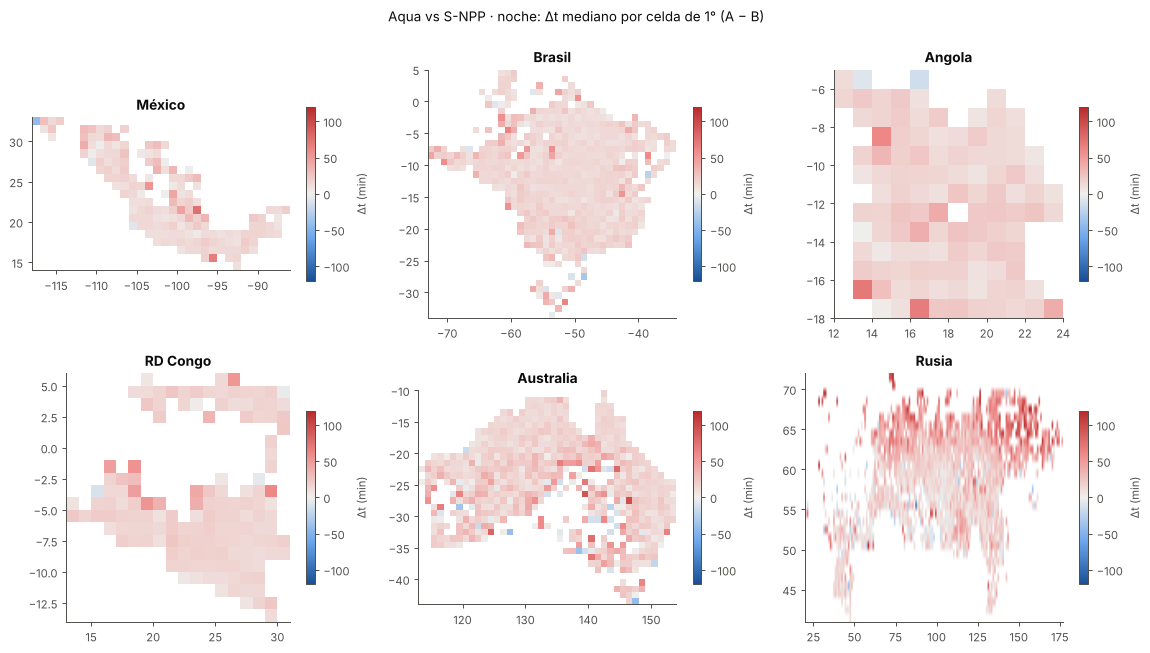

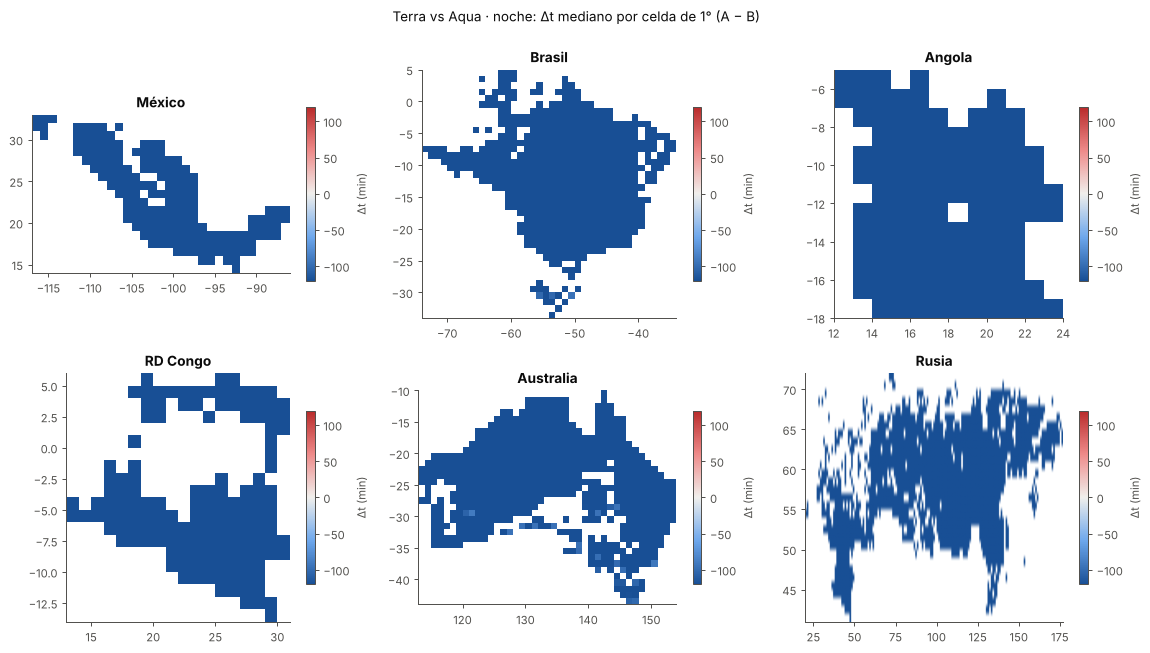

Guardado Data/analisis/02_eda/resultados/celdas_equicomparables_B_60min.csv.gz 111907 filas


In [27]:
for name in PT: dt_map(name, 'N')
cells = pd.concat([m[m.valida & (m.dt.abs() <= 60)].assign(par=n)[['par','country','year','daynight','cell_lat','cell_lon','dt','n_a','n_b']] for n, m in PT.items()])
cells.to_csv(OUT / 'celdas_equicomparables_B_60min.csv.gz', index=False); print('Guardado', OUT / 'celdas_equicomparables_B_60min.csv.gz', len(cells), 'filas')

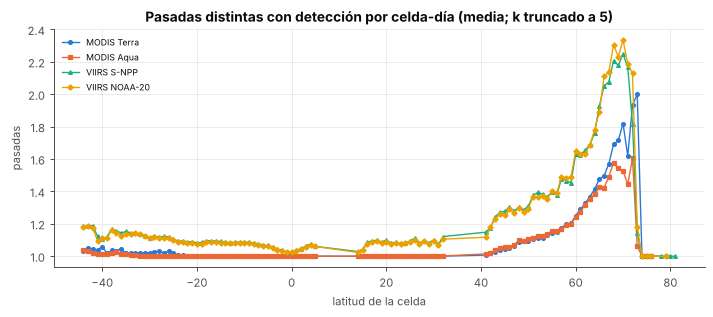

In [28]:
# Proxy de cobertura (j): pasadas distintas con detección por celda-día, según latitud
PL = T['passes_lat']; PL['w'] = PL.k * PL.n_celldays
mp = PL.groupby(['satellite','cell_lat']).apply(lambda d: d.w.sum() / d.n_celldays.sum()).rename('pasadas_medias').reset_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
for s in [x for x in SATS if x in set(mp.satellite)]:
    q = mp[mp.satellite == s].sort_values('cell_lat'); ax.plot(q.cell_lat, q.pasadas_medias, color=SCOL[s], marker=SMK[s], ms=3, lw=1.1, label=SLAB[s])
ax.set(title='Pasadas distintas con detección por celda-día (media; k truncado a 5)', xlabel='latitud de la celda', ylabel='pasadas'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Hallazgos · zonas equicomparables
- **(b)** **Aqua vs S-NPP**: Δt mediano de 9 min (día) y 15 min (noche). Por año, a ±60 min el **99.7–99.9 %** de los hotspots de Aqua cae en celdas comparables de 2012 a 2023, **98.6 % en 2024** (Δt mediano 44 min) y **3.3 % en 2025** (75 min). El puente Aqua↔S-NPP es horariamente válido en 2012–2024 y deja de serlo en 2025. Los promedios de 2012–2025 (±60: 92–96 % de día; ±30: 83–86 %; ±90: 99–100 %) incluyen 2025.
- **(b)** **S-NPP vs NOAA-20**: Δt mediano 0.4 min; ≥ 99.7 % de los hotspots a ±60 min y 95–100 % a ±30 min.
- **(b)** **Terra vs Aqua**: Δt mediano −181 min; 0 % dentro de ±60 min salvo Rusia (22.6 %, por la mayor dispersión de la hora solar a latitud alta). Este par se definió para aislar el efecto de la hora, no para buscar zonas comparables.
- **(b)** En los mapas de Δt de Aqua vs S-NPP, Rusia muestra diferencias mayores a latitudes altas (de noche hasta ≈ +100 min al norte de ≈ 62°N), mientras que en los otros cinco países el Δt es pequeño y homogéneo.
- **Limitación (b):** una celda-año con menos de 5 detecciones en alguno de los dos sensores no se puede evaluar y cuenta como no cubierta. La opción C (restricción de `scan`) no es evaluable con estas tablas; requeriría una agregación adicional de `scan` por celda.

## 9 · Estabilidad de la razón por celda (o)
Referencia: razón mensual S-NPP/NOAA-20 por celda de 1° (misma instrumentación VIIRS). Una celda es **estable** si tiene ≥ 12 meses válidos (ambos ≥ 5 hotspots) y la desviación estándar
del log de la razón es ≤ 0.25 (≈ ±28 %). Luego se prueba si la razón Aqua/S-NPP es más estable dentro de esas celdas.

In [29]:
cmb = CM[['country','satellite','cell_lat','cell_lon','ym','n']]
a = cmb[cmb.satellite == 'N'].drop(columns='satellite'); b = cmb[cmb.satellite == 'N20'].drop(columns='satellite')
j = a.merge(b, on=['country','cell_lat','cell_lon','ym'], suffixes=('_a','_b')); j = j[(j.n_a >= 5) & (j.n_b >= 5)]; j['lr'] = np.log(j.n_a / j.n_b)
cs = j.groupby(['country','cell_lat','cell_lon']).lr.agg(meses='count', media='mean', sd='std').reset_index()
cs['estable'] = (cs.meses >= 12) & (cs.sd <= 0.25); cs.to_csv(OUT / 'celdas_estables_snpp_noaa20.csv', index=False)
tot_ = cmb[cmb.satellite == 'N'].groupby(['country','cell_lat','cell_lon']).n.sum().rename('n_snpp').reset_index().merge(cs, how='left'); tot_['estable'] = tot_.estable.fillna(False)
tab = tot_.groupby('country').apply(lambda d: pd.Series({'celdas con datos S-NPP': len(d), 'celdas evaluables (≥12 meses)': int((d.meses >= 12).sum()), 'celdas estables': int(d.estable.sum()),
        '% de hotspots S-NPP en celdas estables': 100 * d[d.estable].n_snpp.sum() / d.n_snpp.sum(), 'razón mediana S-NPP/NOAA-20 (estables)': float(np.exp(d[d.estable].media.median())) if d.estable.any() else np.nan}))
tab.index = tab.index.map(CSH); display(tab)
st = cs[cs.estable][['country','cell_lat','cell_lon']]
sa = cmb[cmb.satellite.isin(['Aqua','N'])].assign(year=lambda d: d.ym // 100)
def yr_ratio(sub):
    g = sub.groupby(['country','year','satellite']).n.sum().unstack('satellite').dropna(); g['r'] = g.Aqua / g.N; return g
r_all = yr_ratio(sa); r_st = yr_ratio(sa.merge(st))
if len(r_st):
    cmp_ = pd.DataFrame({'CV de la razón anual, todas las celdas': r_all.groupby('country').r.agg(lambda s: s.std() / s.mean()),
                         'CV de la razón anual, celdas estables': r_st.groupby('country').r.agg(lambda s: s.std() / s.mean()),
                         'razón mediana, todas': r_all.groupby('country').r.median(), 'razón mediana, estables': r_st.groupby('country').r.median()})
    cmp_.index = cmp_.index.map(CSH); print('Aqua/S-NPP anual: todas las celdas vs celdas estables'); display(cmp_)
else: print('Sin celdas estables con los datos cargados')

,celdas con datos S-NPP,celdas evaluables (≥12 meses),celdas estables,% de hotspots S-NPP en celdas estables,razón mediana S-NPP/NOAA-20 (estables)
country,,,,,
Angola,140.000,125.000,43.000,38.701,0.980
Australia,809.000,561.000,48.000,16.418,0.992
Brasil,805.000,707.000,50.000,12.929,0.995
RD Congo,237.000,233.000,28.000,19.450,0.975
México,246.000,191.000,44.000,40.527,0.988
Rusia,"2,860.000","1,003.000",174.000,19.774,0.983


Aqua/S-NPP anual: todas las celdas vs celdas estables


,"CV de la razón anual, todas las celdas","CV de la razón anual, celdas estables","razón mediana, todas","razón mediana, estables"
country,,,,
Angola,0.072,0.074,0.206,0.194
Australia,0.062,0.071,0.119,0.119
Brasil,0.051,0.073,0.157,0.141
RD Congo,0.061,0.077,0.208,0.205
México,0.056,0.060,0.122,0.110
Rusia,0.067,0.074,0.113,0.094


### Hallazgos · estabilidad de la razón por celda
- **(b)** Celdas estables (≥ 12 meses válidos y desviación estándar del log de la razón S-NPP/NOAA-20 ≤ 0.25): de 28 (RD Congo) a 174 (Rusia); contienen 12.9 % (Brasil) a 40.5 % (México) de los hotspots de S-NPP. Razón mediana en ellas: 0.975–0.995.
- **(b)** Restringirse a esas celdas **no** hace más estable la razón anual Aqua/S-NPP (CV 6.0–7.7 % frente a 5.1–7.2 % con todas) ni cambia mucho su nivel (p. ej. Rusia 0.094 frente a 0.113). Con esta métrica no aporta.

## 10 · Prototipo de calendario mes × año (conteo y FRP) por país y satélite

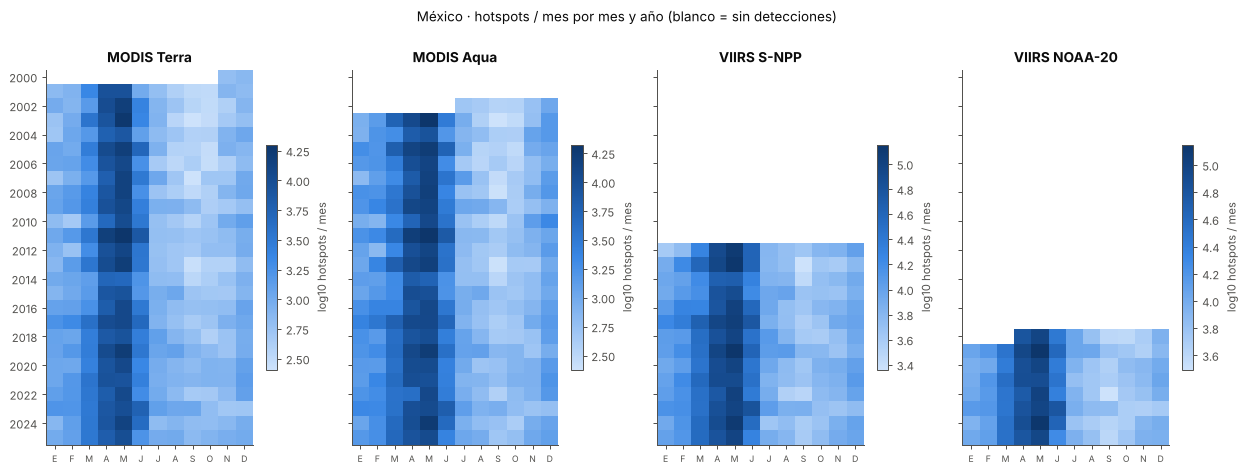

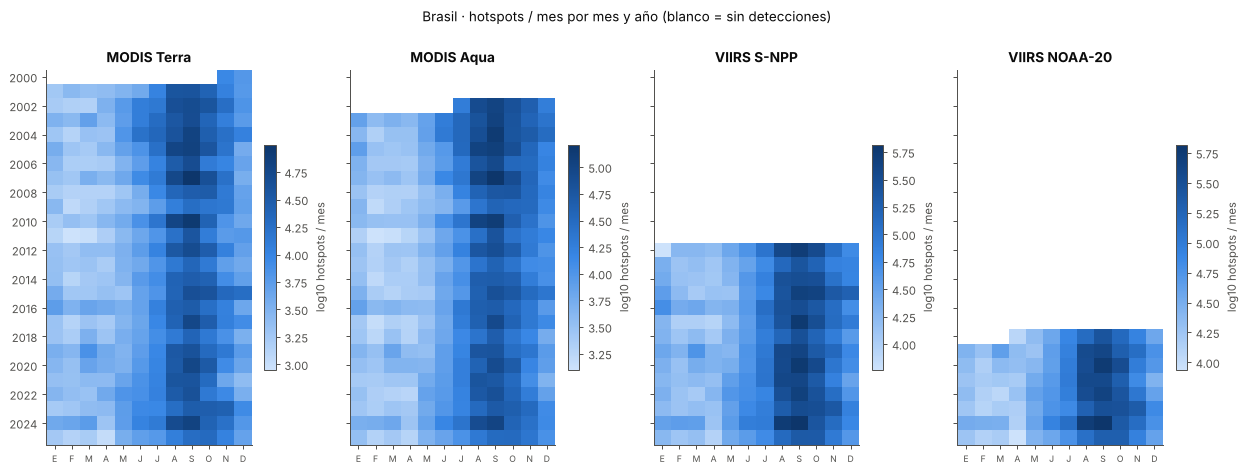

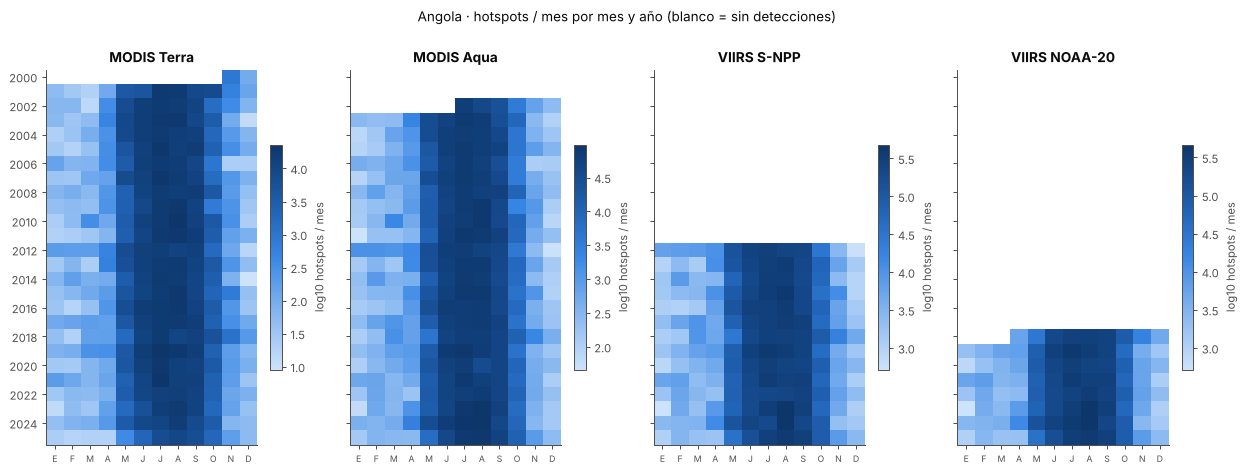

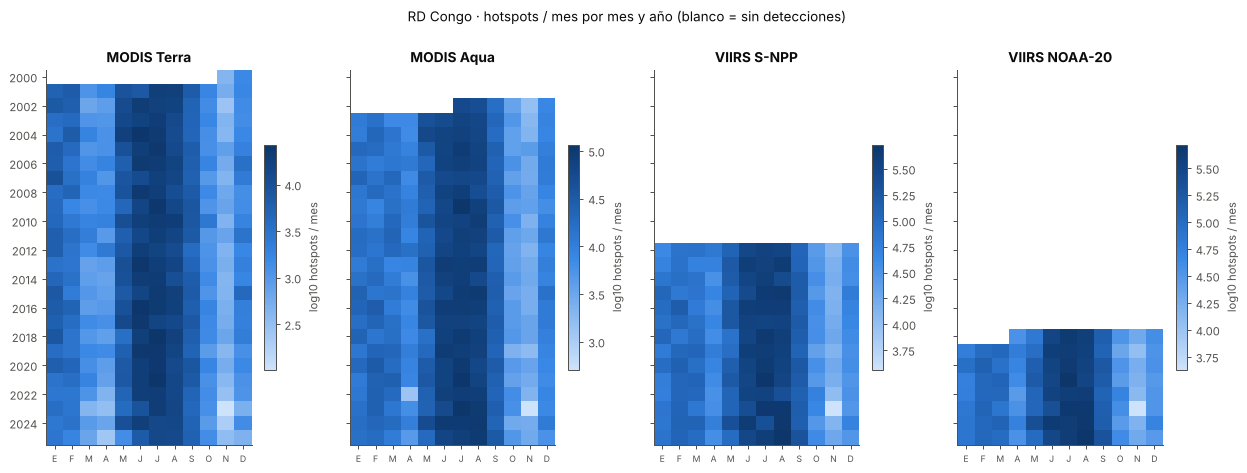

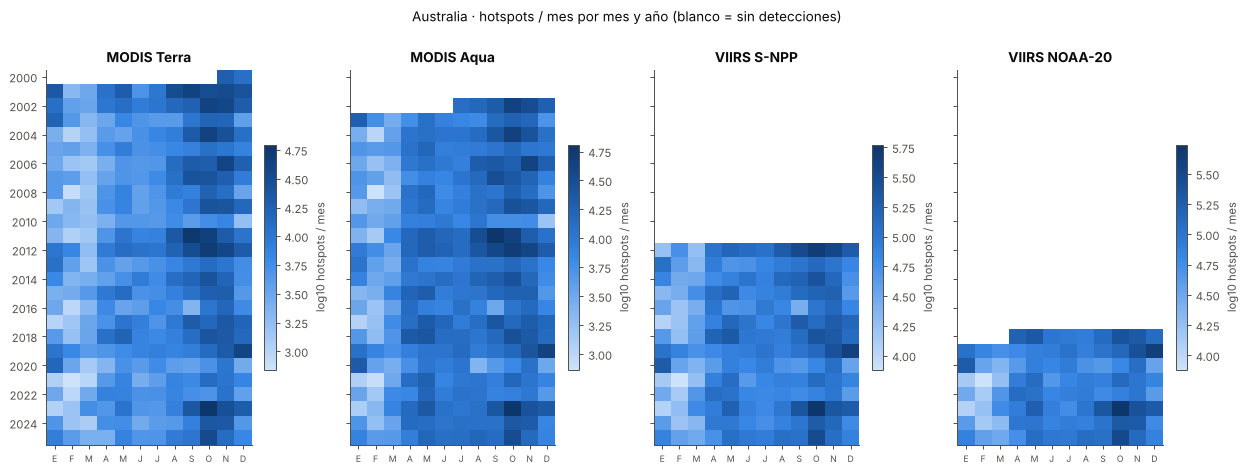

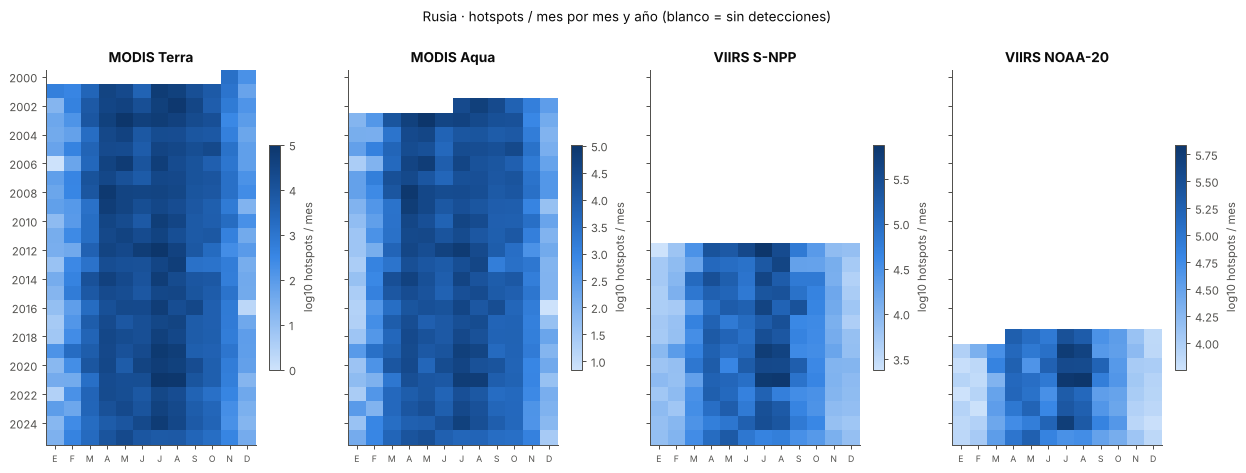

In [30]:
def calendar(c, val, label):
    fig, axs = plt.subplots(1, 4, figsize=(14, 5.2), sharey=True)
    mc = Mm[Mm.country == c]
    for ax, s in zip(axs, SATS):
        q = mc[mc.satellite == s]
        if q.empty: ax.axis('off'); ax.set_title(SLAB[s] + ' (sin datos)'); continue
        piv = q.assign(mes=q.ym % 100).pivot(index='year', columns='mes', values=val).reindex(index=range(2000, 2026), columns=range(1, 13))
        Z = np.log10(piv.where(piv > 0).values.astype(float)); im = ax.imshow(Z, aspect='auto', cmap=BLUES, origin='upper', extent=(.5, 12.5, 2025.5, 1999.5)); ax.grid(False)
        ax.set_title(SLAB[s]); ax.set_xticks(range(1, 13)); ax.set_xticklabels(['E','F','M','A','M','J','J','A','S','O','N','D'], fontsize=7)
        fig.colorbar(im, ax=ax, shrink=.6, label=f'log10 {label}')
    axs[0].set_yticks(range(2000, 2026, 2)); plt.suptitle(f'{CSH[c]} · {label} por mes y año (blanco = sin detecciones)', y=1.0); plt.tight_layout(); plt.show()
for c in COUNTRIES: calendar(c, 'n_all', 'hotspots / mes')

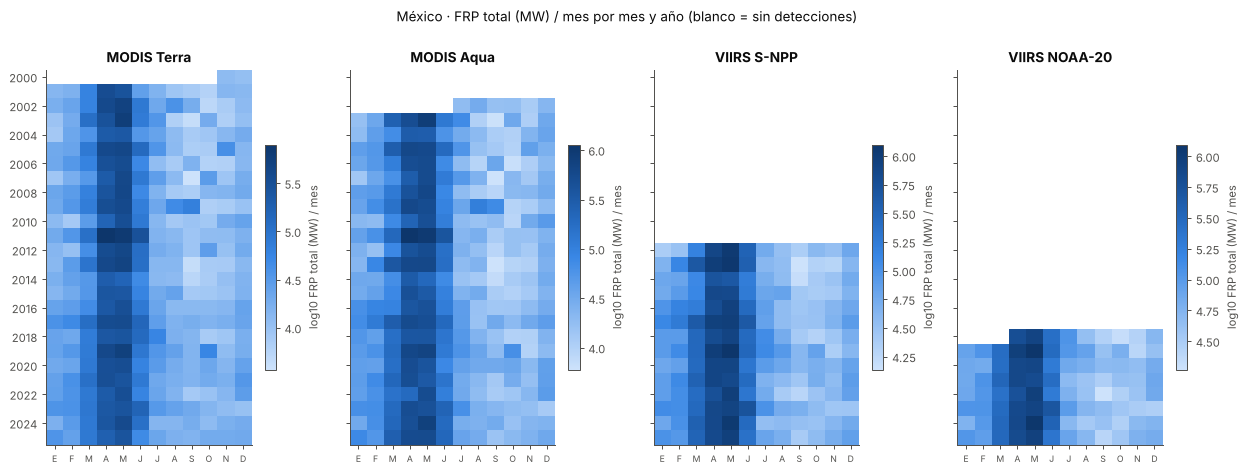

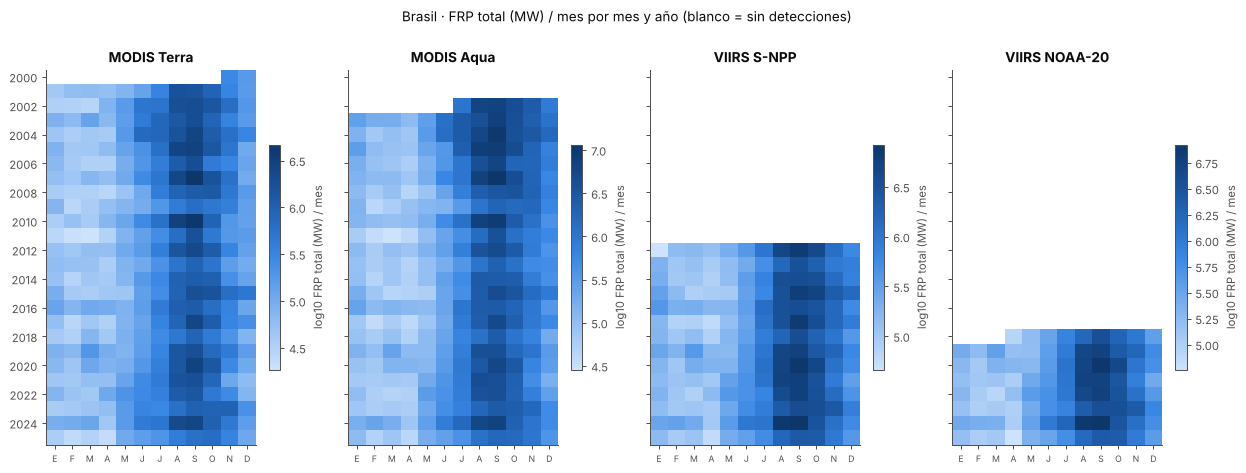

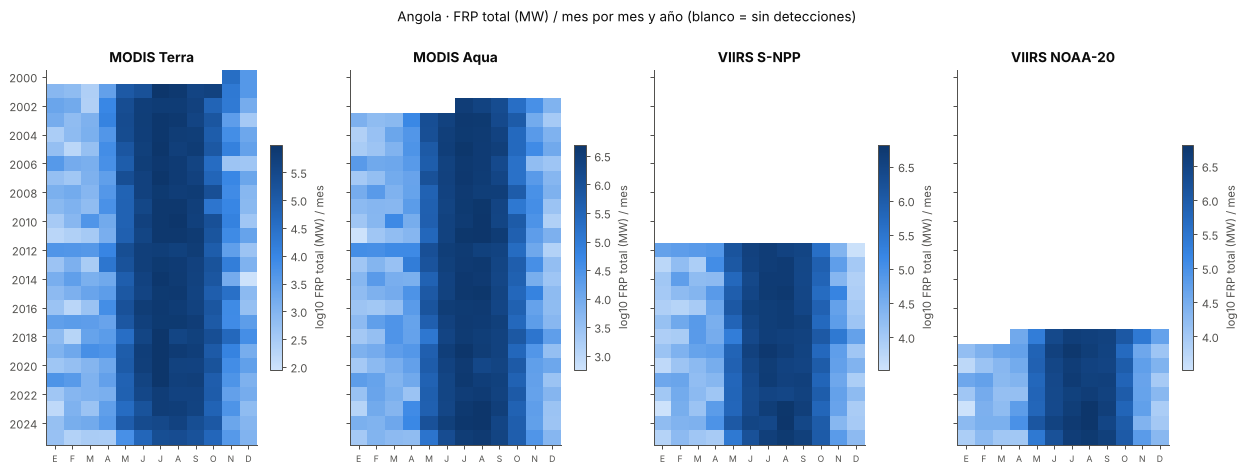

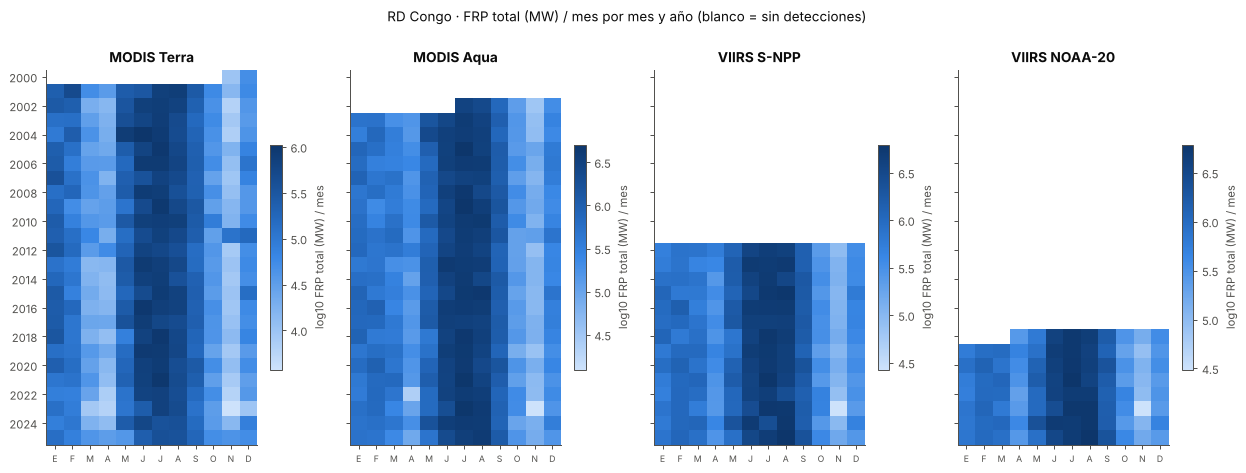

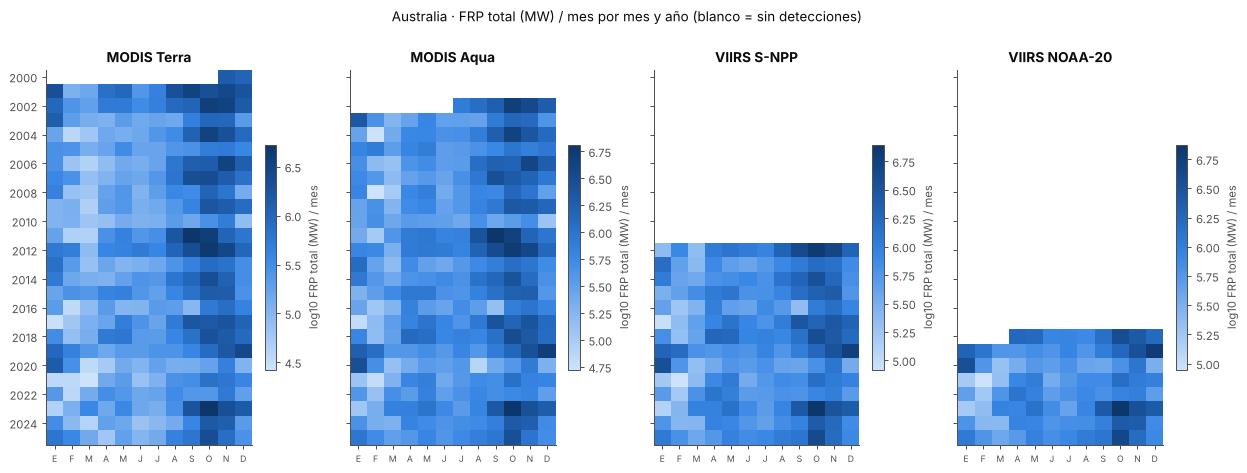

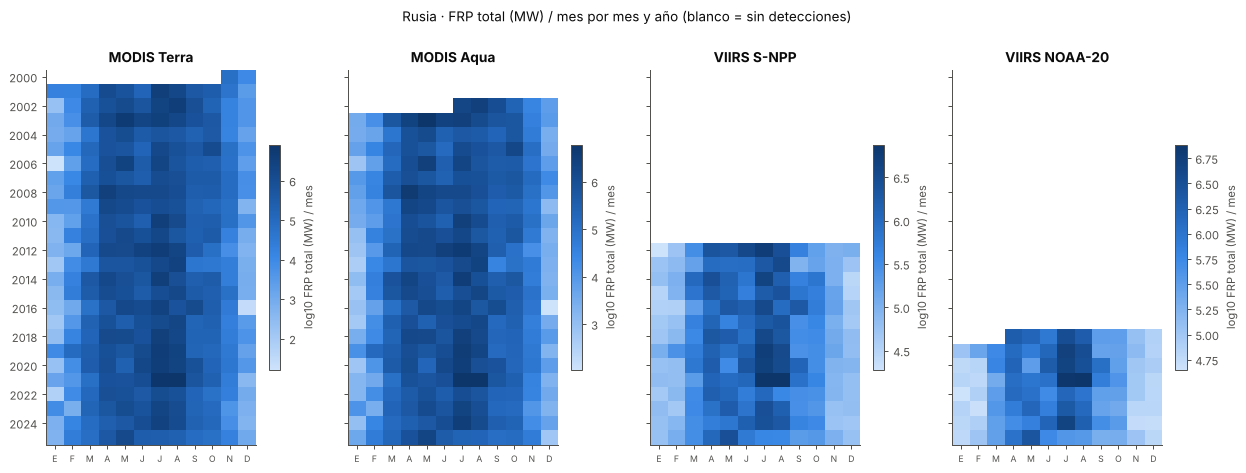

In [31]:
for c in COUNTRIES: calendar(c, 'frp_all', 'FRP total (MW) / mes')

### Hallazgos · calendarios
- **(b)** En Brasil, los cuatro sensores muestran la misma estacionalidad (máximo de agosto a octubre) y arrancan en las fechas esperadas: Terra en nov-2000, Aqua en jul-2002, S-NPP en ene-2012 y NOAA-20 en abr-2018. Los calendarios de los demás países se generan abajo y no se interpretan aquí.

In [32]:
# Tabla central: por país y par, qué parte de los hotspots cae en celdas equicomparables (opción B) y la escala de la diferencia
good = CY[(CY.daynight == 'D') & (CY['cobertura_A_%'] >= 50)].groupby('par').year.apply(list).to_dict()
rows = []
for name, A, B in PAIRS:
    if name not in PT: continue
    m = PT[name]; yrs = good.get(name, [])
    for c in COUNTRIES:
        r = RZ[(RZ.par == name) & (RZ.filtro == 'todo') & (RZ.country == c)]
        d = {'par': name, 'país': CSH[c], 'años con hora comparable': (f'{min(yrs)}–{max(yrs)}' if yrs else 'ninguno'),
             'razón de conteos (mediana)': r.ratio_n.median(), 'razón de FRP (mediana)': r.ratio_frp.median()}
        for dn in ['D','N']:
            g = m[(m.country == c) & (m.year.isin(yrs)) & (m.daynight == dn)]
            for tol in (30, 60, 90):
                ok = g.valida & (g.dt.abs() <= tol)
                d[f'cobertura A {dn} ±{tol}'] = 100 * g[ok].n_a.sum() / max(g.n_a.sum(), 1) if yrs else np.nan
        rows.append(d)
CENTRAL = pd.DataFrame(rows); CENTRAL.to_csv(OUT / 'resumen_por_pais_par.csv', index=False)
display(CENTRAL.round(3))

,par,país,años con hora comparable,razón de conteos (mediana),razón de FRP (mediana),cobertura A D ±30,cobertura A D ±60,cobertura A D ±90,cobertura A N ±30,cobertura A N ±60,cobertura A N ±90
0,S-NPP vs NOAA-20,México,2018–2025,1.015,1.011,99.477,99.960,99.971,98.914,99.919,99.920
1,S-NPP vs NOAA-20,Brasil,2018–2025,1.018,1.006,99.792,99.986,99.987,99.310,99.958,99.962
2,S-NPP vs NOAA-20,Angola,2018–2025,1.012,0.995,99.995,99.999,99.999,99.637,99.969,99.972
3,S-NPP vs NOAA-20,RD Congo,2018–2025,1.008,1.000,99.981,99.999,99.999,98.702,99.668,99.669
4,S-NPP vs NOAA-20,Australia,2018–2025,1.013,0.989,95.657,99.850,99.926,92.236,99.801,99.838
5,S-NPP vs NOAA-20,Rusia,2018–2025,1.010,1.009,94.908,99.657,99.787,94.493,99.653,99.779
6,Aqua vs S-NPP,México,2012–2024,0.122,0.566,90.453,99.669,99.713,84.269,97.211,97.527
7,Aqua vs S-NPP,Brasil,2012–2024,0.157,0.705,89.091,99.770,99.940,80.845,97.715,98.963
8,Aqua vs S-NPP,Angola,2012–2024,0.206,0.759,90.239,99.995,99.995,84.292,95.857,96.766
9,Aqua vs S-NPP,RD Congo,2012–2024,0.208,0.721,90.963,99.998,99.998,86.666,97.830,98.332


## 11 · Síntesis de resultados guardados

### Qué tendría que cumplir una armonización (sin elegir método todavía)
1. La relación entre sensores es **estable en el tiempo pero distinta por país** (conteos Aqua/S-NPP 0.11–0.21; FRP total 0.57–0.76): un factor global no encaja con los datos.
2. La razón depende del **filtro de `confidence`** y la clase `h` no es equivalente entre S-NPP y NOAA-20: hace falta una regla común.
3. La **deriva** de Terra y Aqua rompe la equicomparabilidad horaria: Aqua↔S-NPP vale en 2012–2024 (no en 2025) y Terra no es comparable con VIIRS en ningún año.
4. Los **huecos de datos** sesgan las razones: excluir los meses afectados al calibrar.
5. El **FRP total** se transfiere entre sensores con menos variación entre países que los conteos; el FRP de VIIRS está saturado en ≈ 6.6–7.5 % de los hotspots.
6. Las **fuentes estáticas** pesan hasta ≈ 12 % de los hotspots VIIRS en Rusia y México, pero no explican la diferencia entre países.
7. Antes de 2012 solo hay MODIS (Terra y, desde 2002, Aqua): cualquier transferencia hacia atrás **(c)** supone que la relación observada en 2012–2025 ya era válida.

### Pendientes por verificar (c)
Significado de `version` (6.2, 6.03, 61.03, 2) · significado de `type` en VIIRS · causa de los huecos de datos · si el archivo SP elimina el `l` nocturno del Atlántico Sur y si hay falsos positivos restantes en `n`/`h` · origen de las fuentes persistentes · valor de la restricción de `scan` (opción C), que requiere una agregación adicional.

In [33]:
print('Archivos en', OUT); [print(' ', p.name, f'{p.stat().st_size / 1e6:.2f} MB') for p in sorted(OUT.glob('*'))]

Archivos en Data/analisis/02_eda/resultados
  celdas_equicomparables_B_60min.csv.gz 1.42 MB
  celdas_estables_snpp_noaa20.csv 0.31 MB
  cobertura_equicomparable.csv 0.01 MB
  cobertura_equicomparable_por_anio.csv 0.01 MB
  razones_anuales.csv 0.14 MB
  razones_sin_huecos.csv 0.00 MB
  resumen_por_pais_par.csv 0.00 MB
  umbral_frp_equivalente.csv 0.00 MB


[None, None, None, None, None, None, None, None]